# Predição da indicação de cirurgia valvar na endocardite infecciosa

**Objetivo.** Desenvolver e comparar sete modelos para predizer a **indicação clínica de cirurgia valvar**, utilizando variáveis disponíveis na avaliação inicial de pacientes com endocardite infecciosa. A indicação de cirurgia é diferente da realização efetiva do procedimento.

**Modelos.** Regressão logística, Random Forest, Random Forest + Boruta, XGBoost, LightGBM, CatBoost e TabPFN.

**Análise.** Divisão estratificada 70%/30%; cinco folds externos e três internos; 30 tentativas do Optuna por busca aplicável; otimização final independente no conjunto de treinamento; calibração, AUROC, AUC-PR, Brier, sensibilidade, especificidade, VPP, VPN, F1, IC95%, curvas ROC/PR e SHAP.

**Interpretação.** A figura comparativa destaca o algoritmo com a **maior AUROC observada no teste**. Essa ordenação é descritiva: não é utilizada para reajustar os modelos, e uma validação adicional seria necessária para estimar sem viés o desempenho do vencedor escolhido a partir desse mesmo teste.


## Guia de execução e salvamento

Execute os blocos **em ordem, começando pelo 1**. Cada bloco tem uma função específica, indicada no seu título e nos comentários.

- **Blocos 1–3:** bibliotecas, diretórios, dados, pré-processamento e Boruta.
- **Blocos 4–5:** modelos, Optuna e validação cruzada aninhada. Esta é a etapa mais demorada.
- **Blocos 6–7A:** seleção com base no treinamento; ajuste final dos sete modelos e avaliação no teste.
- **Blocos 7B–9D:** figuras, intervalos de confiança, calibração e comparações.
- **SHAP:** interpretação exploratória do algoritmo com maior AUROC observada no teste.

A **nova pasta de resultados** é criada por execução. O identificador é impresso pelo Bloco 1. Anote-o: para retomar após desconexão, informe o mesmo identificador em `ID_RETOMADA`. O Optuna salva as tentativas concluídas em SQLite; modelos ajustados e predições também são armazenados. **Não reexecute uma busca com outro identificador se sua intenção for retomá-la.**

Os folds e as tentativas do Optuna são executados sequencialmente; cada estimador usa no máximo `N_THREADS_MODELO` núcleos. No RF + Boruta, a seleção é calculada uma vez por fold interno da mesma busca, pois não depende dos hiperparâmetros da floresta final propostos pelo Optuna.

> O tempo total depende do hardware Colab. Otimizar código não elimina o custo de cinco folds externos × 30 tentativas × três folds internos.


**Pré-condição obrigatória:** a planilha `base_modelagem_necessidade_cirurgia.xlsx` precisa existir em `/content/drive/MyDrive/Gitrub/`. Este notebook **não recupera** arquivos excluídos do Drive. Sem a planilha, o Bloco 1 interrompe a execução antes do treinamento.

**Atenção metodológica:** esta é uma nova versão do protocolo de otimização do TabPFN. Como o conjunto de teste foi examinado na análise anterior, qualquer nova comparação nesse mesmo conjunto deve ser descrita como análise adicional/exploratória, e não como validação independente inédita.


## 1. Bibliotecas, caminho do banco e parâmetros reprodutíveis

Execute uma vez no Google Colab. Esta célula define a semente, o número de folds e os caminhos de leitura e saída. A instalação é separada da análise para facilitar a identificação de problemas de ambiente.

In [ ]:
# =============================================================================
# BLOCO 1 — Bibliotecas, configuração e pastas
# =============================================================================

# --- Instalação (só no Colab) -------------------------------------------------
# Bibliotecas de aprendizagem de máquina não necessariamente pré-instaladas. O "-q" deixa a saída curta.
# Fora do Colab, instale uma vez pelo terminal e apague esta linha.
!pip install -q catboost==1.2.10 tabpfn==9.1.0 Boruta==0.4.3 "optuna>=4,<5"

import os
import re
import time
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import lightgbm
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from tabpfn import TabPFNClassifier
import optuna
from sklearn.calibration import CalibratedClassifierCV

# Versões antigas do Boruta usam apelidos do numpy que não existem mais
# (np.float, np.int...). Recriá-los antes do import evita o erro.
for _alias, _tipo in [("float", float), ("int", int), ("bool", bool), ("object", object)]:
    if not hasattr(np, _alias):
        setattr(np, _alias, _tipo)
from boruta import BorutaPy  # noqa: E402

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
matplotlib.rcParams["figure.dpi"] = 110

# --- Colab: Drive e chave do TabPFN --------------------------------------------
# Monta o Drive (onde está a base e onde ficam os resultados) e lê a chave do
# TabPFN guardada nos Secrets do Colab com o nome TABPFN_TOKEN.
# Fora do Colab, o bloco simplesmente não faz nada.
from google.colab import drive, userdata
# Montagem explícita. Falhas não são ocultadas.
drive.mount("/content/drive")
_token_colab = userdata.get("TABPFN_TOKEN")
if not isinstance(_token_colab, str) or not _token_colab.strip():
    raise RuntimeError("Configure TABPFN_TOKEN nos Secrets do Colab e autorize o notebook antes de executar.")
if not _token_colab.isascii() or any(c.isspace() for c in _token_colab):
    raise ValueError("TABPFN_TOKEN inválido: confira a chave nos Secrets do Colab.")
os.environ["TABPFN_TOKEN"] = _token_colab
del _token_colab

# --- Parâmetros principais (alterar somente aqui) -------------------------------
SEED = 42  # mesmo particionamento em execuções repetidas
# Configuração principal: 30 tentativas por algoritmo passível de ajuste
N_TRIALS = 30
CV_EXTERNA = 5
CV_INTERNA = 3
N_BOOT_FINAL = 1000  # bootstrap apenas IC, sem novo treinamento
RODAR_TABPFN = True  # protocolo exige sete algoritmos, incluindo TabPFN
BORUTA_MAX_ITER = 40  # Boruta dentro dos folds, conforme planejamento
# Paralelismo COORDENADO: Optuna e folds são sequenciais; árvores usam até 2 núcleos.
# Evita que bibliotecas disputem todos os CPUs simultaneamente.
N_THREADS_MODELO = max(1, min(2, os.cpu_count() or 1))
BORUTA_PERC = 90  # limiar do Boruta: comparar com variáveis-sombra
MAX_MISSING = 0.70  # remover variáveis com mais de 70% de valores ausentes
IND_MISSING = 0.05  # criar indicadores para variáveis com >=5% ausentes
TEST_SIZE = 0.30  # separação de teste, que não participa da busca
SENS_ALVO = 0.80  # referência clínica para limiar escolhido só no treino

ID = "ID_REGISTRO"
ALVO = "INDICACAO_CIRURGICA"
ARQUIVO = "base_modelagem_necessidade_cirurgia.xlsx"

# Faixas de plausibilidade: valor fora da faixa vira ausente na carga.
# Mesma lista dos notebooks de óbito pós-alta; colunas que não existem nesta base
# são ignoradas.
LIMITES_PLAUSIVEIS = {
    "IDADE": (0, 110), "CREAT_D0": (0, 30), "HB_D0": (2, 25),
    "LEUCO_D0": (0, 100000), "PLAQUETAS_D0": (0, 2000000),
    "FRACO_EJECAO_CARDIACA": (5, 90), "TEMPO_DE_SINTOMAS": (0, 730),
}

# --- Pastas --------------------------------------------------------------------
# A base é procurada primeiro na pasta data/ do repositório e depois no Drive.
PASTA_DRIVE = "/content/drive/MyDrive/Gitrub"
CAMINHOS_DADOS = [os.path.join(PASTA_DRIVE, ARQUIVO), os.path.join("data", ARQUIVO)]

# Nunca direcionar checkpoints para a pasta temporaria "results" no Colab.
# Falhar explicitamente se o Drive ou a base nao estiverem acessiveis.
if not os.path.isdir(PASTA_DRIVE):
    raise FileNotFoundError(f"Pasta do Drive não encontrada: {PASTA_DRIVE}. Restaure o arquivo Excel e a pasta Gitrub antes de continuar.")
if not os.path.isfile(CAMINHOS_DADOS[0]):
    raise FileNotFoundError(f"Base Excel não encontrada: {CAMINHOS_DADOS[0]}. O notebook não pode reconstruir dados clínicos excluídos; restaure a planilha no Drive antes de continuar.")
DIR_RESULTADOS = os.path.join(PASTA_DRIVE, "resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026")
os.makedirs(DIR_RESULTADOS, exist_ok=True)


def salvar_tab(df, nome):
    """Salva uma tabela em CSV; utf-8-sig faz o Excel abrir os acentos certos."""
    df.to_csv(os.path.join(DIR_RESULTADOS, nome), index=False, encoding="utf-8-sig")


def salvar_fig(nome):
    """Salva a figura atual em 300 dpi, mostra no notebook e libera a memória."""
    plt.tight_layout()
    plt.savefig(os.path.join(DIR_RESULTADOS, nome), dpi=300, bbox_inches="tight",
                facecolor="white")
    plt.show()
    plt.close("all")


print(f"Resultados serão salvos em: {DIR_RESULTADOS}")
print(f"Paralelismo controlado: {N_THREADS_MODELO} núcleo(s) por estimador; folds e trials sequenciais.", flush=True)

# =============================================================================
# CHECKPOINTS — ANALISE NOVA E RETOMADA SEGURA
# Uma execucao nova usa um ID diferente. Ao reconectar, mantenha o MESMO ID.
# =============================================================================
import json, hashlib, joblib, tempfile
# Uma execução nova não utiliza resultados de execuções anteriores.
# Na mesma sessão, o identificador permanece o mesmo.
# Gerenciamento seguro de execuções: nunca reutilizar uma pasta antiga por acidente.
# Cada execução deste Bloco 1 cria uma pasta NOVA com identificador único.
# Somente para retomar deliberadamente uma execução interrompida, informe seu ID
# em ID_RETOMADA. A retomada exige que a pasta já exista.
from datetime import datetime, timezone
import uuid
ID_RETOMADA = "20261031_001033_d5dd674c"
_RAZ_EXECUCOES = os.path.join(DIR_RESULTADOS, "execucoes")
os.makedirs(_RAZ_EXECUCOES, exist_ok=True)
if ID_RETOMADA is None:
    ID_EXECUCAO = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8]
    DIR_EXECUCAO = os.path.join(_RAZ_EXECUCOES, ID_EXECUCAO)
    os.makedirs(DIR_EXECUCAO, exist_ok=False)  # impede sobrescrever uma execução existente
    print("[1] NOVA execução criada automaticamente:", ID_EXECUCAO, flush=True)
else:
    if not isinstance(ID_RETOMADA, str) or not __import__("re").fullmatch(r"\d{8}_\d{6}_[0-9a-f]{8}", ID_RETOMADA):
        raise ValueError("ID_RETOMADA inválido; informe o identificador completo da execução.")
    ID_EXECUCAO = ID_RETOMADA
    DIR_EXECUCAO = os.path.join(_RAZ_EXECUCOES, ID_EXECUCAO)
    if not os.path.isdir(DIR_EXECUCAO):
        raise FileNotFoundError("Pasta de retomada inexistente: " + DIR_EXECUCAO)
    print("[1] Retomada solicitada explicitamente:", ID_EXECUCAO, flush=True)
_ID_EXECUCAO_ATUAL = ID_EXECUCAO  # compatibilidade com eventuais células existentes
DIR_CV = os.path.join(DIR_EXECUCAO, "cv_externa")
DIR_MODELOS = os.path.join(DIR_EXECUCAO, "modelos_finais")
DIR_METRICAS = os.path.join(DIR_EXECUCAO, "metricas_teste")
DIR_SHAP = os.path.join(DIR_EXECUCAO, "shap_lotes")
for pasta in [DIR_CV, DIR_MODELOS, DIR_METRICAS, DIR_SHAP]:
    os.makedirs(pasta, exist_ok=True)

def gravar_joblib_atomico(obj, caminho):
    """Grava em arquivo temporario e substitui ao concluir; evita checkpoint truncado."""
    fd, tmp = tempfile.mkstemp(prefix=".checkpoint_", suffix=".joblib", dir=os.path.dirname(caminho))
    os.close(fd)
    try:
        joblib.dump(obj, tmp)
        os.replace(tmp, caminho)
    finally:
        if os.path.exists(tmp): os.remove(tmp)

def gravar_csv_atomico(df, caminho):
    fd, tmp = tempfile.mkstemp(prefix=".checkpoint_", suffix=".csv", dir=os.path.dirname(caminho))
    os.close(fd)
    try:
        df.to_csv(tmp, index=False, encoding="utf-8-sig")
        os.replace(tmp, caminho)
    finally:
        if os.path.exists(tmp): os.remove(tmp)

SLUGS = {"Regressão logística":"logistica", "Random Forest":"rf",
         "Random Forest + Boruta":"rf_boruta", "XGBoost":"xgboost",
         "LightGBM":"lightgbm", "CatBoost":"catboost", "TabPFN":"tabpfn"}
print("\n" + "="*75, flush=True)
print("NOVA PASTA ISOLADA PARA ESTA EXECUÇÃO:", DIR_EXECUCAO, flush=True)
print("Nenhum resultado de pastas anteriores será utilizado.", flush=True)
print("Guarde esse caminho para localizar os arquivos.", flush=True)
print("="*75, flush=True)

# As funções abaixo substituem as versões iniciais para que toda saída
# desta análise seja salva na pasta exclusiva identificada por ID_EXECUCAO.
# Resultado padrão de tabelas e figuras fica na pasta da execução atual.
# Isso não altera a configuração nem o processo de otimização do Optuna.
def salvar_tab(df, nome):
    gravar_csv_atomico(df, os.path.join(DIR_EXECUCAO, nome))

def salvar_fig(nome):
    plt.tight_layout()
    plt.savefig(os.path.join(DIR_EXECUCAO, nome), dpi=300,
                bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close("all")


/tmp/ipykernel_1020/1325476679.py:41: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, _alias):


Mounted at /content/drive
Resultados serão salvos em: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026
Paralelismo controlado: 2 núcleo(s) por estimador; folds e trials sequenciais.
[1] Retomada solicitada explicitamente: 20261031_001033_d5dd674c

NOVA PASTA ISOLADA PARA ESTA EXECUÇÃO: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c
Nenhum resultado de pastas anteriores será utilizado.
Guarde esse caminho para localizar os arquivos.


## 2. Carga e definição da coorte

Lemos a planilha, verificamos IDs, desfecho e limites plausíveis. Colunas potencialmente registradas **após a admissão** devem ser excluídas segundo o dicionário de dados; revise `NAO_ADMISSAO` antes de executar a análise definitiva. A Tabela 1 é apenas descritiva, não define hiperparâmetros.

In [ ]:
# =============================================================================
# BLOCO 2 — Carga da base, faixas de plausibilidade, coorte e Tabela 1
# =============================================================================


def sem_acento(texto):
    """Tira acento e símbolos dos nomes de coluna, para o código não depender do
    encoding com que a planilha foi salva."""
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    texto = re.sub(r"[^0-9a-zA-Z_]+", "_", texto)
    return re.sub(r"_+", "_", texto).strip("_")


def carregar():
    """Lê a base, confirma uma linha por paciente, aplica as faixas de plausibilidade
    e confere se tudo é numérico e se o alvo está em 0/1."""
    caminho = next((c for c in CAMINHOS_DADOS if os.path.exists(c)), None)
    if caminho is None:
        raise FileNotFoundError(f"Não achei {ARQUIVO} em {CAMINHOS_DADOS}")
    d = pd.read_excel(caminho).rename(columns=lambda c: sem_acento(c))
    print(f"Lendo: {caminho}")
    print(f"Dimensão: {d.shape[0]} linhas, {d.shape[1]} colunas")

    # Ordenar pelo ID deixa a divisão treino/teste e os folds reproduzíveis mesmo
    # se a planilha for reexportada em outra ordem.
    d = d.sort_values(ID).reset_index(drop=True)
    repetidos = int(d[ID].duplicated().sum())
    print(f"  IDs repetidos: {repetidos}")
    if repetidos:
        raise ValueError(f"{repetidos} registro(s) repetido(s) em {ID}.")

    # Valor fora da faixa fisiologicamente plausível vira ausente; depois ele é
    # tratado como qualquer dado faltante (imputação dentro do fold).
    for col, (lo, hi) in LIMITES_PLAUSIVEIS.items():
        if col in d.columns:
            fora = (d[col] < lo) | (d[col] > hi)
            print(f"  {col:24s} faixa [{lo}, {hi}]: {int(fora.sum())} valor(es) fora")
            d.loc[fora, col] = np.nan

    # O pré-processamento só aceita números: qualquer texto ou data para aqui.
    nao_numericas = [c for c in d.columns if not pd.api.types.is_numeric_dtype(d[c])]
    if nao_numericas:
        raise ValueError("Colunas não numéricas: " + ", ".join(nao_numericas))
    if not set(d[ALVO].dropna().unique()) <= {0, 1}:
        raise ValueError(f"{ALVO} precisa estar codificado em 0/1.")
    return d


base = carregar()

# --- Coorte --------------------------------------------------------------------
# Alvo vazio significaria paciente não avaliável; ele sai antes de qualquer análise.
elegivel = base[ALVO].notna()
coorte = base.loc[elegivel].reset_index(drop=True)
# Variáveis que NÃO são da admissão: no dicionário do banco, a valva acometida e o
# lado da endocardite vêm da ficha de alta ("prováveis focos cardíacos acometidos"),
# preenchida com toda a informação da internação, inclusive o achado cirúrgico.
# Nos operados elas carregam informação da própria cirurgia, então ficam de fora.
# IRAS_ALGUMA é removida preventivamente da modelagem por possível registro
# posterior à avaliação inicial (potencial vazamento temporal).
# A variável COMPLIC_PERIVALVAR_ADM permanece como preditor, e o Bloco 9C
# avalia separadamente o desempenho no subgrupo SEM complicação perivalvar.
NAO_ADMISSAO = ["MITRAL", "AORTICA", "LADO_DIREITO", "IRAS_ALGUMA"]

# Candidatas: tudo menos ID, alvo e as variáveis que não existem na admissão.
X_df = coorte.drop(columns=[ID, ALVO] + [c for c in NAO_ADMISSAO if c in coorte.columns])
print(f"Retiradas por não serem da admissão: {', '.join(NAO_ADMISSAO)}")
y = coorte[ALVO].astype(int).to_numpy()

n_pos, n_neg = int(y.sum()), int(len(y) - y.sum())
# Pacientes da classe menos frequente por variável candidata (equivalente ao EPV
# quando o desfecho é a classe mais frequente): é a classe menor que limita a informação.
# Aqui o desfecho é o mais frequente, então a classe menor é "sem indicação".
classe_menor = min(n_pos, n_neg)
fluxo = {"n_base": len(base), "excluidos_alvo_vazio": int((~elegivel).sum()),
         "n_analisado": len(coorte), "com_indicacao": n_pos, "sem_indicacao": n_neg,
         "taxa_indicacao": round(n_pos / len(y), 4), "candidatas": X_df.shape[1],
         "classe_menor_por_candidata": round(classe_menor / X_df.shape[1], 1)}
salvar_tab(pd.DataFrame([fluxo]), "tab00_fluxograma.csv")
print()
print(f"Analisados: {fluxo['n_analisado']} (excluídos por alvo vazio: "
      f"{fluxo['excluidos_alvo_vazio']})")
print(f"  com indicação: {n_pos} ({n_pos / len(y):.1%})   sem indicação: {n_neg}")
print(f"  candidatas: {fluxo['candidatas']}   pacientes da classe menor por candidata: "
      f"{fluxo['classe_menor_por_candidata']}")


# --- Tabela 1: características na admissão --------------------------------------
# Variável 0/1 aparece como n (%) de "1" entre quem tem o dado; contínua como
# mediana (intervalo interquartil). Vírgula decimal, pronta para o artigo.
def fmt(x, casas):
    return f"{x:.{casas}f}".replace(".", ",")


def casas_para(valor):
    """Casas decimais conforme a grandeza: 12120 -> 0, 59,0 -> 1, 1,11 -> 2."""
    a = abs(valor)
    return 0 if a >= 100 else 1 if a >= 10 else 2


def descrever(serie, binaria):
    s = serie.dropna()
    if len(s) == 0:
        return "-"
    if binaria:
        k = int(s.sum())
        return f"{k} ({fmt(100 * k / len(s), 1)}%)"
    q1, med, q3 = s.quantile([0.25, 0.50, 0.75])
    c = casas_para(med)
    return f"{fmt(med, c)} ({fmt(q1, c)}-{fmt(q3, c)})"


grupos = {"Total": coorte,
          "Com indicação": coorte[coorte[ALVO] == 1],
          "Sem indicação": coorte[coorte[ALVO] == 0]}
linhas = []
for c in X_df.columns:
    binaria = set(X_df[c].dropna().unique()) <= {0, 1}
    linha = {"variavel": c, "resumo": "n (%)" if binaria else "mediana (IIQ)"}
    for rotulo, g in grupos.items():
        linha[f"{rotulo} (n={len(g)})"] = descrever(g[c], binaria)
    linha["ausente_%"] = fmt(100 * X_df[c].isna().mean(), 1)
    linhas.append(linha)
tabela1 = pd.DataFrame(linhas)
salvar_tab(tabela1, "tab01_caracteristicas_admissao.csv")
print()
print("Tabela 1")
print(tabela1.to_string(index=False))

Lendo: /content/drive/MyDrive/Gitrub/base_modelagem_necessidade_cirurgia.xlsx
Dimensão: 711 linhas, 35 colunas
  IDs repetidos: 0
  IDADE                    faixa [0, 110]: 0 valor(es) fora
  CREAT_D0                 faixa [0, 30]: 0 valor(es) fora
  HB_D0                    faixa [2, 25]: 0 valor(es) fora
  LEUCO_D0                 faixa [0, 100000]: 0 valor(es) fora
  PLAQUETAS_D0             faixa [0, 2000000]: 0 valor(es) fora
  FRACO_EJECAO_CARDIACA    faixa [5, 90]: 0 valor(es) fora
  TEMPO_DE_SINTOMAS        faixa [0, 730]: 0 valor(es) fora
Retiradas por não serem da admissão: MITRAL, AORTICA, LADO_DIREITO, IRAS_ALGUMA

Analisados: 711 (excluídos por alvo vazio: 0)
  com indicação: 459 (64.6%)   sem indicação: 252
  candidatas: 29   pacientes da classe menor por candidata: 8.7

Tabela 1
              variavel        resumo          Total (n=711)  Com indicação (n=459)  Sem indicação (n=252) ausente_%
                  SEXO         n (%)            445 (62,6%)            297 (64,

## 3. Pré-processamento e Boruta dentro dos folds

distinguimos **seleção de variáveis** de **importância das variáveis**. A imputação e a remoção de colunas são aprendidas com o treinamento de cada fold, evitando vazamento. O Boruta só aparece no pipeline `Random Forest + Boruta`; nenhum outro algoritmo herda suas variáveis escolhidas.

In [ ]:
# =============================================================================
# BLOCO 3 — PRÉ-PROCESSAMENTO E SELEÇÃO BORUTA (SEM VAZAMENTO)
# Apenas define classes. fit() ocorre exclusivamente no treino de cada fold.
# Mantém MAX_MISSING, IND_MISSING, BORUTA_MAX_ITER, BORUTA_PERC e SEED do Bloco 1.
# =============================================================================
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.validation import check_is_fitted
from boruta import BorutaPy

class PreProcessador(BaseEstimator, TransformerMixin):
    """Retém preditores numéricos não constantes e com ausência aceitável.

    Ajusta a mediana e define indicadores de ausência SOMENTE no fit.
    Recebe e devolve DataFrame para preservar nomes na seleção Boruta.
    """
    def __init__(self, max_missing=MAX_MISSING, ind_missing=IND_MISSING):
        self.max_missing = max_missing
        self.ind_missing = ind_missing

    def _validar_entrada(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError('PreProcessador requer DataFrame com nomes de variáveis.')
        if not X.columns.is_unique:
            raise ValueError('Existem nomes de colunas duplicados.')
        if X.empty:
            raise ValueError('DataFrame de entrada vazio.')
        # Os preditores foram previamente codificados como números no Bloco 2.
        nao_numericas = X.select_dtypes(exclude='number').columns.tolist()
        if nao_numericas:
            X = X.copy()
            for coluna in nao_numericas:
                try:
                    X[coluna] = pd.to_numeric(X[coluna], errors='raise').astype(float)
                except (TypeError, ValueError) as exc:
                    raise TypeError(f'Preditor não numérico: {coluna}') from exc
        return X

    def fit(self, X, y=None):
        X = self._validar_entrada(X)
        if not (0 <= self.max_missing < 1) or not (0 <= self.ind_missing <= 1):
            raise ValueError('max_missing deve estar em [0,1) e ind_missing em [0,1].')
        if np.isinf(X.to_numpy(dtype=float)).any():
            raise ValueError('Existem valores infinitos; corrija-os antes do treino.')
        frac = X.isna().mean()
        constante = X.nunique(dropna=True) <= 1
        conservar = (frac <= self.max_missing) & (~constante)
        self.colunas_ = X.columns[conservar].tolist()
        self.descartadas_ = X.columns[~conservar].tolist()
        if not self.colunas_:
            raise ValueError('Nenhuma variável permaneceu após o pré-processamento.')
        self.indicadores_ = [c for c in self.colunas_ if frac[c] >= self.ind_missing and frac[c] > 0]
        self.medianas_ = X[self.colunas_].median()
        if self.medianas_.isna().any():
            raise ValueError('Uma variável retida não apresentou mediana válida.')
        self.nomes_ = self.colunas_ + [f'{c}__ausente' for c in self.indicadores_]
        if len(self.nomes_) != len(set(self.nomes_)):
            raise ValueError('Nomes de indicadores de ausência colidem com preditores existentes.')
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        check_is_fitted(self, ['colunas_', 'medianas_', 'nomes_'])
        X = self._validar_entrada(X)
        ausentes = [c for c in self.colunas_ if c not in X.columns]
        if ausentes:
            raise ValueError('Colunas ausentes na transformação: ' + ', '.join(ausentes))
        Z = X.loc[:, self.colunas_].copy()
        indicadores = {f'{c}__ausente': Z[c].isna().astype(float) for c in self.indicadores_}
        Z = Z.fillna(self.medianas_)
        if indicadores:
            Z = pd.concat([Z, pd.DataFrame(indicadores, index=Z.index)], axis=1)
        Z = Z.loc[:, self.nomes_].astype(float)
        if not np.isfinite(Z.to_numpy()).all():
            raise ValueError('O pré-processamento produziu valores não finitos.')
        return Z

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, 'nomes_')
        return np.asarray(self.nomes_, dtype=object)


class SelecaoBoruta(BaseEstimator, TransformerMixin):
    """Boruta seleciona variáveis usando apenas o subconjunto recebido em fit.

    Por padrão inclui variáveis confirmadas e tentativas. Se nenhuma for
    selecionada, utiliza as top_k_minimo importâncias da floresta auxiliar.
    """
    def __init__(self, max_iter=BORUTA_MAX_ITER, perc=BORUTA_PERC,
                 incluir_tentativas=True, top_k_minimo=5, random_state=SEED):
        self.max_iter = max_iter
        self.perc = perc
        self.incluir_tentativas = incluir_tentativas
        self.top_k_minimo = top_k_minimo
        self.random_state = random_state

    def fit(self, X, y):
        if not isinstance(X, pd.DataFrame):
            raise TypeError('Boruta requer o DataFrame gerado pelo PreProcessador.')
        if not X.columns.is_unique or X.shape[1] == 0:
            raise ValueError('Colunas duplicadas ou ausentes na entrada do Boruta.')
        if not np.isfinite(X.to_numpy(dtype=float)).all():
            raise ValueError('Boruta recebeu valores ausentes ou infinitos.')
        y_array = np.asarray(y).ravel()
        if len(y_array) != len(X):
            raise ValueError('Tamanhos diferentes entre X e y no Boruta.')
        if len(np.unique(y_array)) < 2:
            raise ValueError('Boruta requer duas classes no treinamento.')
        if not (1 <= self.perc <= 100):
            raise ValueError('perc do Boruta deve estar entre 1 e 100.')
        if self.max_iter < 2 or self.top_k_minimo < 1:
            raise ValueError('max_iter deve ser >= 2 e top_k_minimo >= 1.')
        nomes = np.asarray(X.columns)
        floresta = RandomForestClassifier(
            n_estimators=300, max_depth=5,
            class_weight='balanced_subsample',
            n_jobs=N_THREADS_MODELO,
            random_state=self.random_state,
        )
        boruta = BorutaPy(
            floresta, n_estimators='auto', perc=self.perc,
            max_iter=self.max_iter, random_state=self.random_state,
            verbose=0,
        )
        boruta.fit(X.to_numpy(dtype=float), y_array)
        self.confirmadas_ = nomes[boruta.support_].tolist()
        self.tentativas_ = nomes[boruta.support_weak_].tolist()
        selecionadas = list(self.confirmadas_)
        if self.incluir_tentativas:
            selecionadas.extend(c for c in self.tentativas_ if c not in selecionadas)
        self.recorreu_ao_plano_b_ = not bool(selecionadas)
        if not selecionadas:
            floresta.fit(X, y_array)
            importancias = pd.Series(floresta.feature_importances_, index=nomes)
            selecionadas = importancias.nlargest(min(self.top_k_minimo, len(nomes))).index.tolist()
        self.selecionadas_ = selecionadas
        self.n_features_in_ = X.shape[1]
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        check_is_fitted(self, 'selecionadas_')
        if not isinstance(X, pd.DataFrame):
            raise TypeError('Boruta requer DataFrame para preservar os nomes.')
        ausentes = [c for c in self.selecionadas_ if c not in X.columns]
        if ausentes:
            raise ValueError('Variáveis selecionadas ausentes: ' + ', '.join(ausentes))
        return X.loc[:, self.selecionadas_].copy()

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, 'selecionadas_')
        return np.asarray(self.selecionadas_, dtype=object)

print('[3] Classes PreProcessador e SelecaoBoruta definidas; sem treinamento.')


[3] Classes PreProcessador e SelecaoBoruta definidas; sem treinamento.


### 4. Modelos e otimização de hiperparâmetros com Optuna

Foram definidos sete algoritmos de aprendizado de máquina supervisionado: regressão logística regularizada, Random Forest, Random Forest associado ao Boruta, XGBoost, LightGBM, CatBoost e TabPFN.

Todos os algoritmos são submetidos à otimização de hiperparâmetros com Optuna, utilizando 30 tentativas e três folds internos, tendo como função objetivo a maximização da AUROC média.

Cada algoritmo possui um espaço de busca específico, adequado à sua arquitetura. No TabPFN, são otimizados parâmetros de configuração e inferência, sem modificar os pesos previamente treinados da rede neural.

O pré-processamento é ajustado exclusivamente nos dados de treinamento de cada fold. No Random Forest associado ao Boruta, a seleção de variáveis também ocorre dentro dos folds, evitando vazamento de informações.

Os estudos do Optuna são armazenados em bancos SQLite com identificadores que permitem distinguir as configurações experimentais e recuperar tentativas concluídas de uma mesma execução.

**Integração com os demais blocos:** o Bloco 5 já contempla a otimização dos sete algoritmos. Os Blocos 7 e 7A serão conferidos antes de sua execução para garantir que o ajuste final utilize o mesmo protocolo e que nenhum algoritmo seja tratado de maneira diferente.

In [ ]:
# =============================================================================
# BLOCO 4 — MODELOS E OTIMIZAÇÃO POR OPTUNA
# =============================================================================
# Este bloco apenas DEFINE funções; não inicia o treinamento dos sete modelos.
# - Trials e folds: sequenciais (n_jobs=1 no Optuna).
# - Paralelismo: limitado dentro de cada estimador (N_THREADS_MODELO).
# - Métrica otimizada: média da AUROC nos folds internos.
# - Checkpoint: SQLite com uma base por estudo, na pasta desta execução.

import os
import time
import json
import hashlib
import warnings
import inspect
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import optuna

# Pré-requisitos dos Blocos 1 e 3: classes dos algoritmos, pipelines, métricas,
# configurações CV_INTERNA/N_TRIALS/SEED, SLUGS, DIR_CV, etc.
# O bloco define funções; a verificação de dependências não treina modelos.


optuna.logging.set_verbosity(optuna.logging.WARNING)

MODELOS_OTIMIZAVEIS = [
    "Regressão logística",
    "Random Forest",
    "Random Forest + Boruta",
    "XGBoost",
    "LightGBM",
    "CatBoost",
    "TabPFN",
]


def montar_modelo(nome, parametros, semente):
    """Constrói o pipeline do algoritmo com os parâmetros escolhidos.

    As etapas `prep` e `boruta` ficam DENTRO do pipeline. Isso garante que,
    em cada fold, elas sejam ajustadas apenas com as observações de treino.
    """
    etapas = [("prep", PreProcessador())]

    if nome == "Random Forest + Boruta":
        etapas.append((
            "boruta",
            SelecaoBoruta(random_state=semente, max_iter=BORUTA_MAX_ITER),
        ))

    if nome == "Regressão logística":
        etapas.append(("escala", StandardScaler()))
        estimador = LogisticRegression(
            solver="saga",
            penalty=parametros["penalty"],
            C=parametros["C"],
            max_iter=8000,
            random_state=semente,
        )

    elif nome in ("Random Forest", "Random Forest + Boruta"):
        estimador = RandomForestClassifier(
            n_estimators=350,
            max_depth=parametros["max_depth"],
            min_samples_leaf=parametros["min_samples_leaf"],
            max_features=parametros["max_features"],
            n_jobs=N_THREADS_MODELO,
            random_state=semente,
        )

    elif nome == "XGBoost":
        estimador = XGBClassifier(
            n_estimators=parametros["n_estimators"],
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=N_THREADS_MODELO,
            random_state=semente,
            **{k: v for k, v in parametros.items() if k != "n_estimators"},
        )

    elif nome == "LightGBM":
        estimador = LGBMClassifier(
            n_estimators=parametros["n_estimators"],
            n_jobs=N_THREADS_MODELO,
            verbosity=-1,
            random_state=semente,
            **{k: v for k, v in parametros.items() if k != "n_estimators"},
        )

    elif nome == "CatBoost":
        estimador = CatBoostClassifier(
            iterations=parametros["iterations"],
            verbose=False,
            allow_writing_files=False,
            thread_count=N_THREADS_MODELO,
            random_seed=semente,
            **{k: v for k, v in parametros.items() if k != "iterations"},
        )
    elif nome == "TabPFN":
        # TabPFN pré-treinado: ajustamos configurações de inferência,
        # não os pesos da rede neural. Valores modestos limitam o custo.
        # Inspeciona a assinatura sem inicializar pesos nem baixar modelos.
        parametros_suportados = inspect.signature(TabPFNClassifier).parameters
        obrigatorios = {"n_estimators", "softmax_temperature", "balance_probabilities", "random_state"}
        ausentes = obrigatorios.difference(parametros_suportados)
        if ausentes:
            raise RuntimeError(
                "TabPFN instalado não aceita os parâmetros necessários: "
                + ", ".join(sorted(ausentes))
                + ". Confira a versão instalada antes da otimização."
            )
        estimador = TabPFNClassifier(
            n_estimators=parametros["n_estimators"],
            softmax_temperature=parametros["softmax_temperature"],
            balance_probabilities=parametros["balance_probabilities"],
            random_state=semente,
        )
    else:
        raise ValueError(f"Modelo não reconhecido: {nome}")

    etapas.append(("clf", estimador))
    return Pipeline(etapas)


def sugerir_params(nome, tentativa):
    """Define o espaço de busca utilizado pelo Optuna em cada algoritmo."""
    t = tentativa

    if nome == "Regressão logística":
        return {
            "penalty": t.suggest_categorical("penalty", ["l1", "l2"]),
            "C": t.suggest_float("C", 0.02, 30.0, log=True),
        }

    if nome in ("Random Forest", "Random Forest + Boruta"):
        return {
            "max_depth": t.suggest_int("max_depth", 2, 10),
            "min_samples_leaf": t.suggest_int("min_samples_leaf", 2, 25),
            "max_features": t.suggest_float("max_features", 0.35, 1.0),
        }

    if nome == "XGBoost":
        return {
            "n_estimators": t.suggest_int("n_estimators", 150, 600, step=50),
            "max_depth": t.suggest_int("max_depth", 1, 4),
            "learning_rate": t.suggest_float("learning_rate", 0.015, 0.15, log=True),
            "min_child_weight": t.suggest_int("min_child_weight", 2, 20),
            "subsample": t.suggest_float("subsample", 0.7, 1.0),
            "colsample_bytree": t.suggest_float("colsample_bytree", 0.7, 1.0),
            "reg_lambda": t.suggest_float("reg_lambda", 0.1, 30.0, log=True),
            "reg_alpha": t.suggest_float("reg_alpha", 0.0001, 5.0, log=True),
            "gamma": t.suggest_float("gamma", 0.0, 3.0),
        }

    if nome == "LightGBM":
        return {
            "n_estimators": t.suggest_int("n_estimators", 150, 600, step=50),
            "max_depth": t.suggest_int("max_depth", 2, 5),
            "num_leaves": t.suggest_int("num_leaves", 3, 15),
            "min_child_samples": t.suggest_int("min_child_samples", 10, 50),
            "learning_rate": t.suggest_float("learning_rate", 0.015, 0.15, log=True),
            "reg_lambda": t.suggest_float("reg_lambda", 0.1, 30.0, log=True),
            "reg_alpha": t.suggest_float("reg_alpha", 0.0001, 5.0, log=True),
            "colsample_bytree": t.suggest_float("colsample_bytree", 0.7, 1.0),
        }

    if nome == "CatBoost":
        return {
            "iterations": t.suggest_int("iterations", 150, 600, step=50),
            "depth": t.suggest_int("depth", 2, 5),
            "learning_rate": t.suggest_float("learning_rate", 0.015, 0.15, log=True),
            "l2_leaf_reg": t.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
            "random_strength": t.suggest_float("random_strength", 0.1, 3.0, log=True),
        }

    if nome == "TabPFN":
        # Busca por 30 trials; a configuração original também está entre as
        # opções (8 estimadores, temperatura padrão 0.9 e sem balanceamento).
        # Temperatura afeta probabilidades; AUROC é a métrica de busca.
        return {
            "n_estimators": t.suggest_categorical("n_estimators", [4, 8, 16]),
            "softmax_temperature": t.suggest_categorical(
                "softmax_temperature", [0.7, 0.9, 1.0, 1.2]
            ),
            "balance_probabilities": t.suggest_categorical(
                "balance_probabilities", [False, True]
            ),
        }

    raise ValueError(f"Não existe espaço de busca para: {nome}")


def otimizar(nome, X, y, seed, n_trials=N_TRIALS):
    """Busca hiperparâmetros no treino, com checkpoint e progresso visível.

    Retorna:
      modelo: pipeline já ajustado na amostra de treino recebida;
      params: melhores hiperparâmetros da busca;
      auc_cv: melhor AUROC média nos três folds internos;
      historico: tabela com as tentativas do Optuna.
    """
    inicio = time.perf_counter()
    X = pd.DataFrame(X).copy()
    y_array = np.asarray(y).ravel()
    if len(X) != len(y_array):
        raise ValueError("X e y têm números diferentes de pacientes.")
    if X.columns.has_duplicates:
        raise ValueError("X contém nomes de colunas duplicados.")
    if pd.isna(X).all(axis=None):
        raise ValueError("X não contém valores observados.")
    if not np.isin(np.unique(y_array), [0, 1]).all() or len(np.unique(y_array)) != 2:
        raise ValueError("O desfecho precisa conter as classes 0 e 1.")
    if n_trials < 1:
        raise ValueError("n_trials deve ser maior ou igual a 1.")
    if np.min(np.bincount(y_array.astype(int))) < CV_INTERNA:
        raise ValueError("Há menos pacientes em uma classe do que folds internos.")
    os.makedirs(DIR_CV, exist_ok=True)

    # A mesma divisão interna é usada em todas as tentativas deste estudo.
    cv_interna = StratifiedKFold(
        n_splits=CV_INTERNA, shuffle=True, random_state=seed
    )
    folds = list(cv_interna.split(X, y_array))
    cache_boruta = None
    registros_boruta = []

    # Uma assinatura diferente gera um novo estudo, inclusive se o espaço de
    # busca, os parâmetros do preprocessamento, o Boruta ou bibliotecas mudarem.
    # Importante: o nome do estudo NÃO é a única proteção. O diretório DIR_CV
    # também deve pertencer a esta execução exclusiva (configurada no Bloco 1).
    dependencias = {
        pacote: metadata.version(pacote)
        for pacote in ("numpy", "pandas", "scikit-learn", "optuna",
                       "xgboost", "lightgbm", "catboost", "tabpfn", "Boruta")
    }
    configuracao = {
        "protocolo": "EI_7_MODELOS_OPTUNA_V7",
        "modelo": nome,
        "seed": int(seed),
        "cv_interna": int(CV_INTERNA),
        "n_trials": int(n_trials),
        "boruta_max_iter": int(BORUTA_MAX_ITER),
        "boruta_perc": int(BORUTA_PERC),
        "max_missing": float(MAX_MISSING),
        "ind_missing": float(IND_MISSING),
        "n_threads": int(N_THREADS_MODELO),
        "pacotes": dependencias,
        # Em Colab, inspect.getsource() pode falhar para classes definidas em
        # células. Versões de protocolo e parâmetros efetivos ficam explícitos.
        "pipeline_version": "preprocessamento_boruta_rev1",
        "espacos_version": "espacos_7_modelos_rev1",
    }
    hash_dados = hashlib.sha256(
        pd.util.hash_pandas_object(X, index=True).values.tobytes()
        + pd.util.hash_pandas_object(pd.Series(y_array), index=False).values.tobytes()
        + repr(tuple(X.columns)).encode("utf-8")
    ).hexdigest()
    configuracao["hash_dados"] = hash_dados
    assinatura = hashlib.sha256(
        json.dumps(configuracao, sort_keys=True, ensure_ascii=False).encode("utf-8")
    ).hexdigest()[:16]
    slug = SLUGS[nome]
    caminho_sqlite = os.path.join(
        DIR_CV, f"optuna_v7_{slug}_{seed}_{assinatura}.sqlite3"
    )
    estudo = optuna.create_study(
        study_name=f"v7_7modelos_{slug}_{seed}_{assinatura}",
        storage=f"sqlite:///{caminho_sqlite}",
        load_if_exists=True,
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=seed),
    )

    concluidas = sum(
        trial.state == optuna.trial.TrialState.COMPLETE
        for trial in estudo.trials
    )
    em_andamento = [t.number for t in estudo.trials if t.state in (
        optuna.trial.TrialState.RUNNING, optuna.trial.TrialState.WAITING
    )]
    if em_andamento:
        raise RuntimeError(
            f"Estudo com tentativas pendentes {em_andamento}. "
            "Verifique se outra sessão ainda usa esse SQLite antes de retomar."
        )
    falhas = sum(t.state == optuna.trial.TrialState.FAIL for t in estudo.trials)
    restantes = max(0, n_trials - concluidas)
    if falhas:
        print(f"    [Optuna] {falhas} tentativa(s) com falha. Serão substituídas para completar {n_trials} válidas.", flush=True)
    if nome == "TabPFN":
        print("    [TabPFN] Otimização de configurações de inferência; "
              "pode ser mais demorada que a dos outros modelos.", flush=True)

    print(
        f"    [Optuna] {nome}: {concluidas}/{n_trials} concluídas; "
        f"faltam {restantes}.",
        flush=True,
    )

    if restantes and nome == "Random Forest + Boruta":
        # IMPORTANTE: o Boruta NÃO depende dos hiperparâmetros candidatos
        # da floresta FINAL; portanto, repetir a seleção 30 vezes por fold
        # seria um desperdício sem alterar o experimento.
        # Cada seleção é ajustada somente ao TREINO do respectivo fold.
        cache_boruta = []
        for numero_fold, (idx_treino, idx_validacao) in enumerate(folds, 1):
            t0 = time.perf_counter()
            print(
                f"    [Boruta] Selecionando no fold interno "
                f"{numero_fold}/{CV_INTERNA}...",
                flush=True,
            )
            prep = PreProcessador().fit(X.iloc[idx_treino], y_array[idx_treino])
            x_treino = prep.transform(X.iloc[idx_treino])
            x_validacao = prep.transform(X.iloc[idx_validacao])
            seletor = SelecaoBoruta(
                random_state=seed + numero_fold - 1,
                max_iter=BORUTA_MAX_ITER,
            )
            seletor.fit(x_treino, y_array[idx_treino])
            for variavel in x_treino.columns:
                registros_boruta.append({
                    "modelo": nome, "seed": seed, "fold_interno": numero_fold,
                    "variavel": variavel,
                    "confirmada": variavel in seletor.confirmadas_,
                    "tentativa": variavel in seletor.tentativas_,
                    "selecionada": variavel in seletor.selecionadas_,
                    "plano_b": bool(seletor.recorreu_ao_plano_b_),
                })
            cache_boruta.append((
                seletor.transform(x_treino),
                seletor.transform(x_validacao),
                y_array[idx_treino],
                y_array[idx_validacao],
            ))
            print(
                f"    [Boruta] Fold {numero_fold}: "
                f"{len(seletor.selecionadas_)} variáveis, "
                f"{time.perf_counter() - t0:.1f}s.",
                flush=True,
            )

        # Registro de estabilidade da seleção, sem usar validação ou teste.
        if registros_boruta:
            arq_sel = os.path.join(DIR_CV, f"boruta_interno_{seed}_{assinatura}.csv")
            gravar_csv_atomico(pd.DataFrame(registros_boruta), arq_sel)
            resumo = (pd.DataFrame(registros_boruta).groupby("variavel")
                      [["confirmada", "tentativa", "selecionada"]].sum()
                      .sort_values("selecionada", ascending=False))
            print("    [Boruta] Frequência de seleção (3 folds):", flush=True)
            print(resumo.head(12).to_string(), flush=True)

    def objetivo(tentativa):
        """Retorna a AUROC média de uma configuração de hiperparâmetros."""
        params = sugerir_params(nome, tentativa)
        pontuacoes = []
        diagnosticos_rl = []

        for k, (idx_treino, idx_validacao) in enumerate(folds):
            if cache_boruta is not None:
                # O pipeline completo seria redundante: prep/Boruta já foram
                # ajustados com o treino deste fold e armazenados no cache.
                x_tr, x_val, y_tr, y_val = cache_boruta[k]
                modelo_fold = montar_modelo(nome, params, seed + k).named_steps["clf"]
                modelo_fold.fit(x_tr, y_tr)
                probabilidades = modelo_fold.predict_proba(x_val)[:, 1]
            else:
                modelo_fold = montar_modelo(nome, params, seed + k)
                # Captura avisos de convergência e identifica modelos constantes.
                with warnings.catch_warnings(record=True) as avisos:
                    warnings.simplefilter("always")
                    modelo_fold.fit(X.iloc[idx_treino], y_array[idx_treino])
                if nome == "Regressão logística":
                    clf = modelo_fold.named_steps["clf"]
                    diagnosticos_rl.append({
                        "fold": k + 1,
                        "n_coef_nao_zero": int(np.count_nonzero(np.abs(clf.coef_) > 1e-10)),
                        "avisos_convergencia": sum(
                            "converge" in str(a.message).lower() for a in avisos
                        ),
                    })
                probabilidades = modelo_fold.predict_proba(X.iloc[idx_validacao])[:, 1]
                y_val = y_array[idx_validacao]

            probabilidades = np.asarray(probabilidades, dtype=float).ravel()
            if len(probabilidades) != len(y_val):
                raise ValueError(f"Probabilidades com tamanho inválido: {nome}, fold {k+1}.")
            if not np.isfinite(probabilidades).all() or np.any((probabilidades < 0) | (probabilidades > 1)):
                raise ValueError(f"Probabilidades fora de [0,1] ou não finitas: {nome}, fold {k+1}.")
            pontuacoes.append(roc_auc_score(y_val, probabilidades))

        if diagnosticos_rl:
            tentativa.set_user_attr("diagnostico_regressao", diagnosticos_rl)
        return float(np.mean(pontuacoes))

    def imprimir_progresso(estudo_atual, tentativa):
        """Mostra o andamento imediatamente após cada tentativa terminada."""
        if tentativa.state != optuna.trial.TrialState.COMPLETE:
            print(f"      Tentativa {tentativa.number} terminou sem AUROC válida: {tentativa.state.name}", flush=True)
            return
        feitas = sum(
            t.state == optuna.trial.TrialState.COMPLETE
            for t in estudo_atual.trials
        )
        print(
            f"      Tentativa {feitas}/{n_trials} | "
            f"AUROC={tentativa.value:.4f} | "
            f"melhor={estudo_atual.best_value:.4f}",
            flush=True,
        )

    # Executa até completar n_trials tentativas VÁLIDAS, sem refazer as
    # anteriores. Em caso de falha inesperada, interrompe para diagnóstico;
    # as tentativas já concluídas ficam preservadas no banco SQLite.
    if restantes:
        estudo.optimize(
            objetivo,
            n_trials=restantes,
            n_jobs=1,
            callbacks=[imprimir_progresso],
            show_progress_bar=False,
        )
    concluidas_apos = sum(
        t.state == optuna.trial.TrialState.COMPLETE for t in estudo.trials
    )
    if concluidas_apos < n_trials:
        raise RuntimeError(
            f"Busca incompleta: {concluidas_apos}/{n_trials} tentativas válidas. "
            "O SQLite foi preservado. Confira os erros antes de retomar."
        )

    if nome == "Regressão logística":
        diagnosticos = []
        for tr in estudo.trials:
            if tr.state == optuna.trial.TrialState.COMPLETE:
                for item in tr.user_attrs.get("diagnostico_regressao", []):
                    diagnosticos.append({"trial": tr.number, "C": tr.params.get("C"),
                                        "penalty": tr.params.get("penalty"), **item})
        if diagnosticos:
            gravar_csv_atomico(pd.DataFrame(diagnosticos),
                os.path.join(DIR_CV, f"diagnostico_regressao_{seed}_{assinatura}.csv"))

    # O modelo devolvido está ajustado apenas ao conjunto de treino recebido.
    # A função NÃO utiliza Xte nem yte.
    parametros = dict(estudo.best_params)
    modelo_final = montar_modelo(nome, parametros, seed)
    modelo_final.fit(X, y_array)
    auc_cv = float(estudo.best_value)
    print(
        f"    [Optuna] {nome} concluído em "
        f"{(time.perf_counter() - inicio)/60:.1f} min; "
        f"AUROC interna={auc_cv:.3f}.",
        flush=True,
    )
    return modelo_final, parametros, auc_cv, estudo.trials_dataframe()


# Pré-verificação sem ajuste: os sete nomes e funções são reconhecidos.
# O TabPFN é verificado pela assinatura do construtor, sem carregar os pesos.
for _nome in MODELOS_OTIMIZAVEIS:
    if _nome not in SLUGS:
        raise RuntimeError(f"SLUGS não contém o modelo {_nome!r}.")
if len(MODELOS_OTIMIZAVEIS) != 7 or len(set(MODELOS_OTIMIZAVEIS)) != 7:
    raise RuntimeError("A lista de modelos contém duplicatas ou não contém sete modelos.")
_parametros_tabpfn = inspect.signature(TabPFNClassifier).parameters
_faltantes_tabpfn = {
    "n_estimators", "softmax_temperature", "balance_probabilities", "random_state"
} - set(_parametros_tabpfn)
if _faltantes_tabpfn:
    raise RuntimeError(
        "TabPFN não oferece os argumentos esperados: " + ", ".join(sorted(_faltantes_tabpfn))
    )
print("[4] Sete algoritmos definidos; TabPFN aceita os argumentos previstos; sem treinamento.", flush=True)


[4] Sete algoritmos definidos; TabPFN aceita os argumentos previstos; sem treinamento.


### 5. Validação cruzada aninhada e predições OOF

A validação cruzada aninhada utiliza cinco folds externos e três folds internos. Em cada fold externo, os sete algoritmos — regressão logística, Random Forest, Random Forest associado ao Boruta, XGBoost, LightGBM, CatBoost e TabPFN — são submetidos à otimização de hiperparâmetros com Optuna, utilizando 30 tentativas por algoritmo.

Os hiperparâmetros são selecionados com base na maior AUROC média dos três folds internos. Em seguida, cada modelo é ajustado aos dados de treinamento do respectivo fold externo e avaliado nas observações de validação, que não participaram da otimização.

O pré-processamento e a seleção de variáveis pelo Boruta são realizados exclusivamente nos dados de treinamento de cada fold, evitando vazamento de informações.

As probabilidades *out-of-fold* (OOF) são armazenadas para a comparação posterior dos sete algoritmos. O conjunto de teste permanece reservado e não participa da otimização nem da seleção dos modelos.

O progresso das tentativas é exibido durante a execução, e os resultados são salvos em checkpoints para permitir a retomada de uma execução interrompida.

In [ ]:
# =============================================================================
# BLOCO 5 — PARTICIONAMENTO E VALIDAÇÃO CRUZADA ANINHADA (7 MODELOS)
# =============================================================================
# Pressupõe Blocos 1–4 executados em sessão limpa.
# - Teste estratificado, isolado antes da otimização.
# - 5 folds externos; Optuna com 30 tentativas / 3 folds internos em TODOS,
#   inclusive o TabPFN.
# - Pré-processamento e Boruta são ajustados dentro do treino de cada fold.
# - Checkpoints somente da execução atual, validados por assinatura.
# - As predições OOF são posicionadas na ordem original de Xtr/ytr.
# - NENHUMA métrica do teste é calculada aqui.
# =============================================================================
# As bibliotecas principais já foram importadas no Bloco 1.
# Importação adicional usada apenas para registrar versões instaladas.
import importlib.metadata as metadata

# Atualizar esta versão se mudarem as regras de otimização, CV ou predição.
VERSAO_PROTOCOLO_B5 = "nested_all7_preflight_boruta_records_v2"

necessarios = [
    "y", "X_df", "TEST_SIZE", "SEED", "N_TRIALS", "CV_EXTERNA", "CV_INTERNA",
    "BORUTA_MAX_ITER", "BORUTA_PERC", "N_THREADS_MODELO", "MAX_MISSING",
    "IND_MISSING", "SENS_ALVO", "DIR_EXECUCAO", "DIR_CV", "SLUGS",
    "MODELOS_OTIMIZAVEIS", "otimizar", "gravar_joblib_atomico",
    "gravar_csv_atomico", "montar_modelo", "sugerir_params",
    "os", "json", "hashlib", "np", "pd", "joblib", "train_test_split",
    "StratifiedKFold", "roc_auc_score", "PreProcessador", "SelecaoBoruta", "optuna",
]
ausentes = [chave for chave in necessarios if chave not in globals()]
if ausentes:
    raise RuntimeError("Blocos anteriores incompletos: " + ", ".join(ausentes))

nomes = list(MODELOS_OTIMIZAVEIS)
if "TabPFN" not in nomes:
    raise RuntimeError(
        "Esta análise exige TabPFN presente "
        "em MODELOS_OTIMIZAVEIS no Bloco 4."
    )
if len(nomes) != 7 or len(set(nomes)) != 7:
    raise RuntimeError(f"Esperados sete algoritmos únicos; recebidos: {nomes}")
if int(N_TRIALS) != 30 or int(CV_INTERNA) != 3 or int(CV_EXTERNA) != 5:
    raise RuntimeError("Protocolo definido: 30 trials, 3 folds internos e 5 externos.")
if not np.isclose(float(TEST_SIZE), 0.30):
    raise ValueError("O protocolo acordado exige TEST_SIZE = 0.30 (treino 70%, teste 30%).")

os.makedirs(DIR_EXECUCAO, exist_ok=True)
os.makedirs(DIR_CV, exist_ok=True)
y_array_b5 = np.asarray(y).ravel()
if not isinstance(X_df, pd.DataFrame) or len(X_df) != len(y_array_b5):
    raise ValueError("X_df deve ser DataFrame alinhado com y.")
if not np.isin(np.unique(y_array_b5), [0, 1]).all() or len(np.unique(y_array_b5)) != 2:
    raise ValueError("O desfecho y deve conter as classes 0 e 1.")

# Reproduzir a mesma divisão sem substituir nem inspecionar o teste.
idx_tr, idx_te = train_test_split(
    np.arange(len(y_array_b5)), test_size=TEST_SIZE, random_state=SEED, stratify=y_array_b5
)
Xtr = X_df.iloc[idx_tr].reset_index(drop=True)
Xte = X_df.iloc[idx_te].reset_index(drop=True)
ytr = y_array_b5[idx_tr]
yte = y_array_b5[idx_te]
print(
    f"[5] Treino: {len(ytr)} | teste reservado: {len(yte)} | "
    f"positivos no treino: {ytr.mean():.1%}", flush=True
)

if min(np.bincount(ytr.astype(int))) < CV_EXTERNA * CV_INTERNA:
    raise ValueError("Poucas observações por classe para a CV aninhada planejada.")

# -----------------------------------------------------------------------------
# PRÉ-VALIDAÇÃO INTEGRADA — MESMO CRITÉRIO PARA OS SETE ALGORITMOS
# -----------------------------------------------------------------------------
# Executa UMA configuração de cada pipeline numa amostra pequena do TREINAMENTO.
# Não utiliza Xte/yte, não chama Optuna e não altera os modelos definitivos.
# O teste não prova que todas as 30 configurações irão funcionar, mas antecipa
# problemas de biblioteca, autenticação, seleção, ajuste ou predict_proba.
# Reutiliza train_test_split e optuna importados anteriormente.

print("[5] Pré-validação de funcionamento: sete algoritmos, mesmo procedimento.", flush=True)
_indices_amostra, _ = train_test_split(
    np.arange(len(ytr)), train_size=min(120, len(ytr)-2),
    stratify=ytr, random_state=SEED + 717
)
_y_amostra = np.asarray(ytr)[_indices_amostra]
_a_amostra, _v_amostra = train_test_split(
    np.arange(len(_indices_amostra)), test_size=0.25,
    stratify=_y_amostra, random_state=SEED + 718
)
_X_a = Xtr.iloc[_indices_amostra].iloc[_a_amostra]
_X_v = Xtr.iloc[_indices_amostra].iloc[_v_amostra]
_y_a = _y_amostra[_a_amostra]

for _nome in nomes:
    _estudo_teste = optuna.create_study(direction="maximize")  # em memória
    _trial_teste = _estudo_teste.ask()
    _params_teste = sugerir_params(_nome, _trial_teste)
    _modelo_teste = montar_modelo(_nome, _params_teste, SEED + 719)
    try:
        _modelo_teste.fit(_X_a, _y_a)
        _p = np.asarray(_modelo_teste.predict_proba(_X_v)[:, 1], dtype=float)
        if len(_p) != len(_X_v) or not np.isfinite(_p).all() or ((_p < 0) | (_p > 1)).any():
            raise RuntimeError("probabilidades fora de [0,1], ausentes ou de tamanho incorreto")
    except Exception as _erro:
        raise RuntimeError(
            f"[PRÉ-VALIDAÇÃO] {_nome} falhou antes do Optuna: "
            f"{type(_erro).__name__}: {_erro}"
        ) from _erro
    print(f"    [OK] {_nome}: fit e predict_proba; {_p.size} predições válidas.", flush=True)

# Libera os objetos da pré-validação; não são usados na CV definitiva.
del _X_a, _X_v, _y_a, _p, _modelo_teste, _estudo_teste
print("[5] Pré-validação dos sete modelos concluída. Iniciando CV aninhada.", flush=True)

# A identidade inclui versão do protocolo, base, partição e bibliotecas.
# Uma pasta antiga com outro protocolo deve causar ERRO, não retomada silenciosa.
versoes = {}
for pacote in (
    "numpy", "pandas", "scikit-learn", "optuna", "xgboost", "lightgbm",
    "catboost", "tabpfn", "Boruta"
):
    versoes[pacote] = metadata.version(pacote)

hash_X = hashlib.sha256(
    pd.util.hash_pandas_object(X_df, index=True).values.tobytes()
).hexdigest()
hash_y = hashlib.sha256(y_array_b5.tobytes()).hexdigest()
identidade = {
    "versao_protocolo": VERSAO_PROTOCOLO_B5,
    "dados_X": hash_X, "dados_y": hash_y,
    "colunas": list(map(str, X_df.columns)),
    "indices_treino": idx_tr.tolist(), "indices_teste": idx_te.tolist(),
    "modelos": nomes,
    "seed": int(SEED), "test_size": float(TEST_SIZE),
    "trials": int(N_TRIALS), "cv_externa": int(CV_EXTERNA),
    "cv_interna": int(CV_INTERNA),
    "boruta_iter": int(BORUTA_MAX_ITER),
    "boruta_perc": float(BORUTA_PERC),
    "threads_modelo": int(N_THREADS_MODELO),
    "max_missing": MAX_MISSING,
    "ind_missing": IND_MISSING,
    "sens_alvo": float(SENS_ALVO),
    "versoes": versoes,
}
# Torna tipos NumPy e outras estruturas JSON-safe, sem mudar semântica.
def _json_normalizar(obj):
    if isinstance(obj, np.generic):
        return obj.item()
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, (set, tuple)):
        return list(obj)
    raise TypeError(f"Tipo não serializável na identidade: {type(obj).__name__}")

identidade = json.loads(json.dumps(identidade, default=_json_normalizar, sort_keys=True))
assinatura_execucao = hashlib.sha256(
    json.dumps(identidade, sort_keys=True, ensure_ascii=False).encode("utf-8")
).hexdigest()

arquivo_identidade = os.path.join(DIR_EXECUCAO, "identidade_execucao.json")
if os.path.isfile(arquivo_identidade):
    with open(arquivo_identidade, encoding="utf-8") as f:
        anterior = json.load(f)
    if anterior != identidade:
        raise RuntimeError(
            "A pasta atual contém checkpoints de uma configuração diferente. "
            "A execução foi interrompida para proteger os resultados. "
            "É necessário criar uma nova execução pelo Bloco 1; "
            "não apague os resultados anteriores."
        )
else:
    # Falhar caso existam folds antigos mesmo sem arquivo de identidade.
    if any(f.startswith("fold_") and f.endswith(".joblib") for f in os.listdir(DIR_CV)):
        raise RuntimeError(
            "Encontrados folds anteriores sem identidade_execucao.json. "
            "A execução foi interrompida para proteger os resultados. "
            "É necessário criar uma nova execução pelo Bloco 1."
        )
    caminho_tmp = arquivo_identidade + ".tmp"
    with open(caminho_tmp, "w", encoding="utf-8") as f:
        json.dump(identidade, f, ensure_ascii=False, indent=2)
    os.replace(caminho_tmp, arquivo_identidade)

print("[5] Identidade validada; sete algoritmos com Optuna.", flush=True)

oof = {nome: np.full(len(ytr), np.nan, dtype=float) for nome in nomes}
registros = []
registros_boruta_externos = []
externa = StratifiedKFold(n_splits=CV_EXTERNA, shuffle=True, random_state=SEED)

for fold, (a, v) in enumerate(externa.split(Xtr, ytr), start=1):
    print(f"\n[5] Fold externo {fold}/{CV_EXTERNA}", flush=True)
    for nome in nomes:
        print(f"  [Fold {fold}/{CV_EXTERNA}] {nome}", flush=True)
        guardado = None
        registros_boruta_fold = []
        arquivo_fold = os.path.join(DIR_CV, f"fold_{fold}_{SLUGS[nome]}.joblib")
        if os.path.isfile(arquivo_fold):
            guardado = joblib.load(arquivo_fold)
            if (
                guardado.get("assinatura_execucao") != assinatura_execucao
                or guardado.get("modelo") != nome
                or guardado.get("fold") != fold
                or not np.array_equal(guardado.get("indices_validacao"), v)
            ):
                raise RuntimeError("Checkpoint incompatível: " + arquivo_fold)
            preds = np.asarray(guardado["probabilidades"], dtype=float).ravel()
            params = guardado["hiperparametros"]
            auc_int = float(guardado["AUROC_interna"])
            print("    Recuperado checkpoint validado.", flush=True)
        else:
            # Inclui TabPFN: nenhum ramo especial de fit sem Optuna.
            modelo, params, auc_int, estudo = otimizar(
                nome, Xtr.iloc[a], ytr[a], SEED + fold * 1000,
                n_trials=N_TRIALS,
            )
            # Boruta EXTERNO: seletor já ajustado somente com treino do fold.
            # Registrar confirmadas, tentativas e selecionadas sem consultar v.
            registros_boruta_fold = []
            if nome == "Random Forest + Boruta":
                seletor_externo = modelo.named_steps["boruta"]
                prep_externo = modelo.named_steps["prep"]
                nomes_candidatos = list(prep_externo.nomes_)
                for variavel in nomes_candidatos:
                    registros_boruta_fold.append({
                        "fold_externo": fold,
                        "variavel": variavel,
                        "confirmada": variavel in seletor_externo.confirmadas_,
                        "tentativa": variavel in seletor_externo.tentativas_,
                        "selecionada": variavel in seletor_externo.selecionadas_,
                        "plano_b": bool(seletor_externo.recorreu_ao_plano_b_),
                    })
                print(f"    [Boruta] Fold externo {fold}: "
                      f"{len(seletor_externo.selecionadas_)} selecionadas; "
                      f"{len(seletor_externo.confirmadas_)} confirmadas.", flush=True)
            preds = np.asarray(
                modelo.predict_proba(Xtr.iloc[v])[:, 1], dtype=float
            ).ravel()
            # Guardar o histórico antes do checkpoint do fold.
            gravar_csv_atomico(
                estudo,
                os.path.join(DIR_CV, f"optuna_fold_{fold}_{SLUGS[nome]}.csv")
            )
            # Somente um checkpoint COMPLETO e válido permite retomar o fold.
            if (
                len(preds) != len(v) or not np.isfinite(preds).all()
                or np.any((preds < 0) | (preds > 1))
            ):
                raise RuntimeError("Predições inválidas de " + nome)
            gravar_joblib_atomico(
                {
                    "assinatura_execucao": assinatura_execucao,
                    "modelo": nome, "fold": fold,
                    "indices_validacao": np.asarray(v),
                    "probabilidades": preds,
                    "hiperparametros": params,
                    "AUROC_interna": float(auc_int),
                    "registros_boruta_fold": registros_boruta_fold,
                },
                arquivo_fold,
            )

        if (
            len(preds) != len(v) or not np.isfinite(preds).all()
            or np.any((preds < 0) | (preds > 1))
        ):
            raise RuntimeError("Checkpoint/predições inválidas: " + nome)
        if not np.isfinite(auc_int):
            raise RuntimeError("AUROC interna ausente para: " + nome)
        if nome == "Random Forest + Boruta":
            # Na retomada, recupera o registro salvo no checkpoint do fold.
            registros_boruta_fold = (
                guardado.get("registros_boruta_fold", [])
                if isinstance(guardado, dict)
                else registros_boruta_fold
            )
            if not registros_boruta_fold:
                raise RuntimeError(
                    "Checkpoint do RF+Boruta sem registro de seleção externa. "
                    "Não é seguro inferir a seleção a partir dos demais folds."
                )
            registros_boruta_externos.extend(registros_boruta_fold)
            gravar_csv_atomico(
                pd.DataFrame(registros_boruta_externos),
                os.path.join(DIR_CV, "boruta_selecao_folds_externos_parcial.csv"),
            )
        auc_externa = float(roc_auc_score(ytr[v], preds))
        oof[nome][v] = preds
        registros.append({
            "fold": fold, "modelo": nome, "AUROC_interna": float(auc_int),
            "AUROC_validacao": auc_externa,
            "hiperparametros": str(params),
        })
        gravar_csv_atomico(
            pd.DataFrame(registros),
            os.path.join(DIR_CV, "hiperparametros_por_fold_parcial.csv")
        )
        print(f"    Concluído: AUROC externa = {auc_externa:.3f}", flush=True)

if not all(np.isfinite(prob).all() for prob in oof.values()):
    raise RuntimeError("Predições OOF incompletas: algum fold não foi preenchido.")

# Salvar artefatos requeridos pelos Blocos 6–7A.
gravar_csv_atomico(
    pd.DataFrame(registros),
    os.path.join(DIR_EXECUCAO, "hiperparametros_por_fold.csv")
)
grava_oof = {
    "ytreino": ytr, "oof": oof,
    "idx_treino": idx_tr, "idx_teste": idx_te,
    "assinatura_execucao": assinatura_execucao,
}
gravar_joblib_atomico(
    grava_oof,
    os.path.join(DIR_EXECUCAO, "predicoes_oof_treino.pkl")
)
print("\n[5] Validação cruzada concluída; OOF de 7 modelos salvas.", flush=True)

# Frequência de seleção EXTERNA (5 folds). Descritiva, sem consulta ao teste.
if registros_boruta_externos:
    tabela_boruta_externa = pd.DataFrame(registros_boruta_externos)
    gravar_csv_atomico(
        tabela_boruta_externa,
        os.path.join(DIR_CV, "boruta_selecao_folds_externos.csv"),
    )
    frequencias_boruta = (
        tabela_boruta_externa.groupby("variavel", as_index=False)
        .agg(
            folds_disponiveis=("fold_externo", "nunique"),
            vezes_confirmada=("confirmada", "sum"),
            vezes_tentativa=("tentativa", "sum"),
            vezes_selecionada=("selecionada", "sum"),
        )
        .sort_values(["vezes_selecionada", "vezes_confirmada"], ascending=False)
    )
    frequencias_boruta["frequencia_5_folds_pct"] = (
        frequencias_boruta["vezes_selecionada"] / CV_EXTERNA * 100
    )
    gravar_csv_atomico(
        frequencias_boruta,
        os.path.join(DIR_CV, "boruta_frequencia_selecao_externa.csv"),
    )
    print("[5] Seleção externa pelo Boruta registrada e resumida:", flush=True)
    print(frequencias_boruta.head(20).to_string(index=False), flush=True)

print("[5] Validação aninhada concluída; probabilidades OOF salvas.", flush=True)

[5] Treino: 497 | teste reservado: 214 | positivos no treino: 64.6%
[5] Pré-validação de funcionamento: sete algoritmos, mesmo procedimento.
    [OK] Regressão logística: fit e predict_proba; 30 predições válidas.
    [OK] Random Forest: fit e predict_proba; 30 predições válidas.
    [OK] Random Forest + Boruta: fit e predict_proba; 30 predições válidas.
    [OK] XGBoost: fit e predict_proba; 30 predições válidas.
    [OK] LightGBM: fit e predict_proba; 30 predições válidas.
    [OK] CatBoost: fit e predict_proba; 30 predições válidas.
    [OK] TabPFN: fit e predict_proba; 30 predições válidas.
[5] Pré-validação dos sete modelos concluída. Iniciando CV aninhada.
[5] Identidade validada; sete algoritmos com Optuna.

[5] Fold externo 1/5
  [Fold 1/5] Regressão logística
    Recuperado checkpoint validado.
    Concluído: AUROC externa = 0.763
  [Fold 1/5] Random Forest
    Recuperado checkpoint validado.
    Concluído: AUROC externa = 0.740
  [Fold 1/5] Random Forest + Boruta
    [Optuna]

## 6. Métricas na validação cruzada e seleção do vencedor

As métricas seguem a lógica da Monitoria 4: AUROC (discriminação), AUC-PR, sensibilidade, especificidade, VPP, VPN e Brier (erro quadrático das probabilidades). A escolha do melhor algoritmo usa **somente AUROC nas predições OOF do treino**, com Brier como desempate. Não usamos o teste para escolher o vencedor.

O limiar classificatório é definido a partir das probabilidades OOF do modelo escolhido para buscar sensibilidade de 80%; isso não altera a AUROC.

In [ ]:

# ============================================================
# BLOCO 6 — COMPARAÇÃO DOS SETE ALGORITMOS POR PREDIÇÕES OOF
# ============================================================
# Executar SOMENTE após concluir o Bloco 5.
#
# - Sem escolha de campeão.
# - Sem meta de 80% de sensibilidade.
# - Sem acesso ao conjunto de teste.
# - Threshold fixo de 0,50 para todos os algoritmos.
#
# AUROC, AUC-PR e Brier independem do threshold.
# ============================================================


from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    f1_score
)


# ============================================================
# 1. VERIFICAR AS DEPENDÊNCIAS DO BLOCO 5
# ============================================================

_necessarios_b6 = ("ytr", "oof", "nomes", "salvar_tab")

_ausentes_b6 = [
    n for n in _necessarios_b6
    if n not in globals()
]

if _ausentes_b6:
    raise RuntimeError(
        "Dependências ausentes; conclua os Blocos 1–5: "
        + ", ".join(_ausentes_b6)
    )


# ============================================================
# 2. VALIDAR AS PREDIÇÕES OOF
# ============================================================

_y_b6 = np.asarray(ytr).ravel()

if (
    len(_y_b6) == 0
    or not np.array_equal(np.unique(_y_b6), [0, 1])
):
    raise ValueError(
        "ytr precisa conter observações das classes 0 e 1."
    )

if (
    len(nomes) != 7
    or len(set(nomes)) != 7
    or set(oof.keys()) != set(nomes)
):
    raise RuntimeError(
        "O Bloco 6 exige exatamente os sete "
        "algoritmos definidos no Bloco 5."
    )

for _nome_b6 in nomes:

    _p_b6 = np.asarray(
        oof[_nome_b6], dtype=float
    ).ravel()

    if len(_p_b6) != len(_y_b6):
        raise RuntimeError(
            f"OOF de {_nome_b6} não corresponde "
            "ao tamanho do treinamento."
        )

    if not np.isfinite(_p_b6).all():
        raise RuntimeError(
            f"OOF de {_nome_b6} contém NaN "
            "ou infinito. Verifique o Bloco 5."
        )

    if np.any((_p_b6 < 0) | (_p_b6 > 1)):
        raise RuntimeError(
            f"OOF de {_nome_b6} contém "
            "probabilidades fora de [0, 1]."
        )

print(
    f"[6] Predições OOF validadas: "
    f"{len(_y_b6)} pacientes e "
    f"{len(nomes)} algoritmos.",
    flush=True
)


# ============================================================
# 3. FUNÇÃO DE AVALIAÇÃO DOS MODELOS
# ============================================================

def desempenho(yreal, p, lim=0.50):

    yreal = np.asarray(yreal).ravel()
    p = np.asarray(p, dtype=float).ravel()

    if len(yreal) == 0 or len(yreal) != len(p):
        raise ValueError(
            "yreal e p devem ter o mesmo "
            "tamanho e não podem estar vazios."
        )

    if not np.array_equal(
        np.unique(yreal), [0, 1]
    ):
        raise ValueError(
            "A amostra precisa conter as "
            "classes 0 e 1 para calcular AUROC."
        )

    if (
        not np.isfinite(p).all()
        or np.any((p < 0) | (p > 1))
    ):
        raise ValueError(
            "As probabilidades devem ser finitas "
            "e estar no intervalo [0, 1]."
        )

    if (
        not np.isfinite(lim)
        or not (0 <= lim <= 1)
    ):
        raise ValueError(
            "O limiar precisa estar entre 0 e 1."
        )

    # Classificação usando o limiar escolhido
    pred = (p >= lim).astype(int)

    # Matriz de confusão
    tn, fp, fn, tp = confusion_matrix(
        yreal,
        pred,
        labels=[0, 1]
    ).ravel()

    # Evitar divisão por zero
    def razao(num, den):
        return (
            float(num / den)
            if den
            else float("nan")
        )

    return {
        "AUROC": float(
            roc_auc_score(yreal, p)
        ),

        "AUC_PR": float(
            average_precision_score(yreal, p)
        ),

        "Brier": float(
            brier_score_loss(yreal, p)
        ),

        "sensibilidade": razao(
            tp, tp + fn
        ),

        "especificidade": razao(
            tn, tn + fp
        ),

        "VPP": razao(
            tp, tp + fp
        ),

        "VPN": razao(
            tn, tn + fn
        ),

        "F1_score": float(
            f1_score(
                yreal,
                pred,
                pos_label=1,
                zero_division=0
            )
        )
    }


# ============================================================
# 4. DEFINIR O THRESHOLD FIXO
# ============================================================
# O mesmo limiar será utilizado para todos os modelos.
# Nenhum threshold será otimizado com base no teste.

limiar = 0.50

print(
    f"\n[6] Threshold fixo: {limiar:.2f}",
    flush=True
)


# ============================================================
# 5. CALCULAR AS MÉTRICAS DOS SETE ALGORITMOS
# ============================================================

resultados = []

for nome in nomes:

    metricas = desempenho(
        yreal=_y_b6,
        p=oof[nome],
        lim=limiar
    )

    resultados.append({
        "modelo": nome,
        "limiar": limiar,
        **metricas
    })


# ============================================================
# 6. ORGANIZAR A TABELA COMPARATIVA
# ============================================================
# A ordenação pela AUROC é apenas descritiva.
# Nenhum algoritmo será selecionado ou excluído.
#
# O Brier funciona como segundo critério de ordenação
# quando há igualdade da AUROC.

tabela_cv = (
    pd.DataFrame(resultados)
    .sort_values(
        ["AUROC", "Brier", "modelo"],
        ascending=[False, True, True]
    )
    .reset_index(drop=True)
)

print(
    "\n[6] Comparação OOF dos sete algoritmos:",
    flush=True
)

display(tabela_cv.round(3))


# ============================================================
# 7. SALVAR A TABELA COMPARATIVA
# ============================================================

salvar_tab(
    tabela_cv,
    "comparacao_validacao_cruzada_treino.csv"
)

print(
    "\n[6] Tabela comparativa salva.",
    flush=True
)


# ============================================================
# 8. FINALIZAÇÃO
# ============================================================

print(
    "\n[6] Comparação OOF concluída.",
    flush=True
)

print(
    "[6] Nenhum campeão foi escolhido.",
    flush=True
)

print(
    "[6] Os sete algoritmos seguirão para "
    "treinamento final e avaliação no teste.",
    flush=True
)


[6] Predições OOF validadas: 497 pacientes e 7 algoritmos.

[6] Threshold fixo: 0.50

[6] Comparação OOF dos sete algoritmos:


,modelo,limiar,AUROC,AUC_PR,Brier,sensibilidade,especificidade,VPP,VPN,F1_score
0,TabPFN,0.5,0.771,0.867,0.184,0.829,0.483,0.745,0.607,0.785
1,LightGBM,0.5,0.765,0.857,0.185,0.838,0.455,0.737,0.606,0.784
2,XGBoost,0.5,0.764,0.856,0.185,0.829,0.438,0.729,0.583,0.776
3,Random Forest,0.5,0.761,0.857,0.190,0.900,0.330,0.710,0.644,0.794
4,CatBoost,0.5,0.757,0.855,0.186,0.891,0.409,0.733,0.673,0.805
5,Regressão logística,0.5,0.750,0.841,0.192,0.900,0.335,0.712,0.648,0.795
6,Random Forest + Boruta,0.5,0.704,0.818,0.203,0.913,0.261,0.693,0.622,0.788



[6] Tabela comparativa salva.

[6] Comparação OOF concluída.
[6] Nenhum campeão foi escolhido.
[6] Os sete algoritmos seguirão para treinamento final e avaliação no teste.


## 7. Ajuste final dos sete algoritmos de aprendizado de máquina

Os sete algoritmos — regressão logística, Random Forest, Random Forest + Boruta, XGBoost, LightGBM, CatBoost e TabPFN — são submetidos à otimização final de hiperparâmetros com Optuna, utilizando exclusivamente o conjunto completo de treinamento (n = 497).

Após a otimização, cada algoritmo é ajustado com todos os pacientes do treinamento, mantendo o pré-processamento e, quando aplicável, a seleção de variáveis pelo Boruta dentro do pipeline.

Os modelos finais, seus hiperparâmetros e os resultados da otimização são armazenados individualmente para garantir a rastreabilidade e a reprodutibilidade.

Nenhum algoritmo é selecionado ou excluído com base no desempenho OOF do Bloco 6. Todos os sete modelos seguirão para avaliação independente no conjunto de teste reservado (n = 214), realizada no Bloco 7A.

A avaliação da calibração e a eventual recalibração das probabilidades serão conduzidas em análises complementares, sem utilizar o conjunto de teste para ajustar os modelos.

In [ ]:
# =============================================================================
# BLOCO 7 — AJUSTE FINAL DOS SETE ALGORITMOS (SEM TESTE E SEM CAMPEAO)
# =============================================================================
# Depende dos Blocos 1–6. As importacoes sao centralizadas no Bloco 1.
# Ajusta cada algoritmo em TODOS os 497 pacientes de treinamento, usando
# a funcao otimizar() do Bloco 4 (Optuna, 30 tentativas, CV interna 3 folds).
# Cada modelo treinado e salvo individualmente com metadados e assinatura.
# NAO ACESSA Xte ou yte; nao aplica recalibracao nesta etapa.
# =============================================================================

_necessarios_7 = [
    'os', 'time', 'hashlib', 'joblib', 'np', 'pd', 'Xtr', 'ytr', 'oof',
    'MODELOS_OTIMIZAVEIS', 'SLUGS', 'SEED', 'N_TRIALS', 'CV_INTERNA',
    'DIR_MODELOS', 'otimizar', 'gravar_joblib_atomico', 'gravar_csv_atomico',
]
_faltando_7 = [k for k in _necessarios_7 if k not in globals()]
if _faltando_7:
    raise RuntimeError('Bloco 7: faltam dependencias: ' + ', '.join(_faltando_7))

nomes_finais = list(MODELOS_OTIMIZAVEIS)
if len(nomes_finais) != 7 or len(set(nomes_finais)) != 7:
    raise RuntimeError('O Bloco 7 exige exatamente os sete algoritmos.')
if set(oof) != set(nomes_finais):
    raise RuntimeError('OOF e modelos configurados nao coincidem.')

_y7 = np.asarray(ytr).ravel()
if len(Xtr) != len(_y7) or len(np.unique(_y7)) != 2:
    raise ValueError('Xtr/ytr invalidos.')
if not hasattr(Xtr, 'columns') or Xtr.columns.has_duplicates:
    raise ValueError('Xtr precisa ser DataFrame com colunas unicas.')
for _nome in nomes_finais:
    _p = np.asarray(oof[_nome], dtype=float).ravel()
    if len(_p) != len(_y7) or not np.isfinite(_p).all() or ((_p < 0) | (_p > 1)).any():
        raise RuntimeError('OOF incompleta/invalida: ' + _nome)

os.makedirs(DIR_MODELOS, exist_ok=True)

# Esta assinatura evita reutilizar automaticamente modelos de outra base,
# configuracao ou protocolo. Nao substitui auditoria do codigo fonte.
def _assinatura_final_7():
    _h = hashlib.sha256()
    _h.update(b'EI_SETE_MODELOS_FINAL_V1_OPTUNA_30_CV_INTERNA')
    _h.update(str((int(SEED), int(N_TRIALS), int(CV_INTERNA), tuple(nomes_finais))).encode())
    _h.update(str(tuple(Xtr.columns)).encode())
    _h.update(pd.util.hash_pandas_object(Xtr, index=True).values.tobytes())
    _h.update(pd.util.hash_pandas_object(pd.Series(_y7), index=False).values.tobytes())
    # Adiciona a identidade do protocolo vigente quando disponivel.
    for _k in ('MAX_MISSING', 'IND_MISSING', 'BORUTA_MAX_ITER', 'BORUTA_PERC', 'N_THREADS_MODELO'):
        _h.update(f'{_k}={globals().get(_k, None)!r}'.encode())
    return _h.hexdigest()

assinatura_final_7 = _assinatura_final_7()
modelos_finais = {}
parametros_finais_7 = {}
registros_finais_7 = []

print(f'[7] Ajuste final dos 7 algoritmos | treino={len(_y7)} | Optuna={N_TRIALS} tentativas.', flush=True)
print('[7] Nao ha selecao de campeao nem acesso ao teste.', flush=True)

for _i, _nome in enumerate(nomes_finais, 1):
    _slug = SLUGS[_nome]
    _arquivo = os.path.join(DIR_MODELOS, f'modelo_final_v1_{_slug}.joblib')
    _metadados = os.path.join(DIR_MODELOS, f'metadata_final_v1_{_slug}.joblib')
    _inicio = time.perf_counter()
    _seed = int(SEED) + 9000  # mesma semente de CV interna para comparar algoritmos
    print(f'\n[7] {_i}/7 — {_nome}', flush=True)

    _recuperado = False
    if os.path.isfile(_arquivo) and os.path.isfile(_metadados):
        _meta = joblib.load(_metadados)
        if (isinstance(_meta, dict)
                and _meta.get('protocolo') == 'EI_7_FINAL_V1'
                and _meta.get('assinatura') == assinatura_final_7
                and _meta.get('modelo') == _nome
                and _meta.get('seed') == _seed
                and _meta.get('n_trials') == int(N_TRIALS)):
            _modelo = joblib.load(_arquivo)
            _parametros = dict(_meta['parametros'])
            _auc_interna = float(_meta['AUROC_interna'])
            _recuperado = True
            print('  Checkpoint individual compativel recuperado.', flush=True)
        else:
            raise RuntimeError(
                f'Checkpoint anterior incompativel para {_nome}. '
                'Preserve os arquivos antigos e utilize uma pasta de execucao nova.'
            )
    else:
        if os.path.isfile(_arquivo) != os.path.isfile(_metadados):
            raise RuntimeError(f'Checkpoint parcial de {_nome}; confira antes de continuar.')
        _modelo, _parametros, _auc_interna, _historico = otimizar(
            _nome, Xtr, _y7, _seed, n_trials=N_TRIALS
        )
        gravar_csv_atomico(
            _historico, os.path.join(DIR_MODELOS, f'optuna_final_v1_{_slug}.csv')
        )
        gravar_joblib_atomico(_modelo, _arquivo)
        gravar_joblib_atomico({
            'protocolo': 'EI_7_FINAL_V1', 'modelo': _nome,
            'assinatura': assinatura_final_7, 'seed': _seed,
            'n_trials': int(N_TRIALS), 'cv_interna': int(CV_INTERNA),
            'parametros': dict(_parametros), 'AUROC_interna': float(_auc_interna),
            'n_treino': len(_y7), 'colunas': list(Xtr.columns),
        }, _metadados)

    modelos_finais[_nome] = _modelo
    parametros_finais_7[_nome] = dict(_parametros)
    registros_finais_7.append({
        'modelo': _nome, 'AUROC_interna_ajuste_final': float(_auc_interna),
        'checkpoint_recuperado': _recuperado,
        'duracao_segundos_nesta_execucao': round(time.perf_counter() - _inicio, 1),
        'parametros': str(_parametros),
    })
    gravar_csv_atomico(pd.DataFrame(registros_finais_7),
        os.path.join(DIR_MODELOS, 'resumo_ajuste_final_sete_modelos.csv'))
    print(f'  Concluido: AUROC interna={_auc_interna:.3f}; modelo salvo.', flush=True)

resumo_final_7 = pd.DataFrame(registros_finais_7)
display(resumo_final_7)
print('[7] Sete modelos ajustados e salvos. Pronto para Bloco 7A.', flush=True)


[7] Ajuste final dos 7 algoritmos | treino=497 | Optuna=30 tentativas.
[7] Nao ha selecao de campeao nem acesso ao teste.

[7] 1/7 — Regressão logística
    [Optuna] Regressão logística: 0/30 concluídas; faltam 30.
      Tentativa 1/30 | AUROC=0.7724 | melhor=0.7724
      Tentativa 2/30 | AUROC=0.7726 | melhor=0.7726
      Tentativa 3/30 | AUROC=0.7724 | melhor=0.7726
      Tentativa 4/30 | AUROC=0.7796 | melhor=0.7796
      Tentativa 5/30 | AUROC=0.7725 | melhor=0.7796
      Tentativa 6/30 | AUROC=0.7755 | melhor=0.7796
      Tentativa 7/30 | AUROC=0.7725 | melhor=0.7796
      Tentativa 8/30 | AUROC=0.7723 | melhor=0.7796
      Tentativa 9/30 | AUROC=0.7771 | melhor=0.7796
      Tentativa 10/30 | AUROC=0.7810 | melhor=0.7810
      Tentativa 11/30 | AUROC=0.7786 | melhor=0.7810
      Tentativa 12/30 | AUROC=0.7808 | melhor=0.7810
      Tentativa 13/30 | AUROC=0.7796 | melhor=0.7810
      Tentativa 14/30 | AUROC=0.7782 | melhor=0.7810
      Tentativa 15/30 | AUROC=0.7792 | melhor=0.7810

,modelo,AUROC_interna_ajuste_final,checkpoint_recuperado,duracao_segundos_nesta_execucao,parametros
0,Regressão logística,0.781228,False,16.2,"{'penalty': 'l2', 'C': 0.06062935117610586}"
1,Random Forest,0.756561,False,120.6,"{'max_depth': 7, 'min_samples_leaf': 5, 'max_f..."
2,Random Forest + Boruta,0.719033,False,155.8,"{'max_depth': 3, 'min_samples_leaf': 7, 'max_f..."
3,XGBoost,0.768721,False,44.7,"{'n_estimators': 450, 'max_depth': 3, 'learnin..."
4,LightGBM,0.773689,False,31.9,"{'n_estimators': 450, 'max_depth': 4, 'num_lea..."
5,CatBoost,0.767260,False,63.2,"{'iterations': 450, 'depth': 2, 'learning_rate..."
6,TabPFN,0.774795,False,9219.2,"{'n_estimators': 16, 'softmax_temperature': 1...."


[7] Sete modelos ajustados e salvos. Pronto para Bloco 7A.


## 7A. Avaliação independente e comparação dos sete algoritmos no conjunto de teste

Os sete algoritmos — regressão logística, Random Forest, Random Forest + Boruta, XGBoost, LightGBM, CatBoost e TabPFN — previamente otimizados e ajustados no conjunto completo de treinamento (Bloco 7), são avaliados no conjunto de teste reservado (n = 214).

O desempenho preditivo é avaliado por AUROC, AUC-PR e escore de Brier. Adicionalmente, são calculados sensibilidade, especificidade, valor preditivo positivo, valor preditivo negativo e F1-score, utilizando um limiar fixo de probabilidade de 0,50 para todos os algoritmos.

São estimados intervalos de confiança de 95% por bootstrap para as métricas previstas no protocolo. Também são comparadas as AUROCs obtidas no ajuste aparente ao treinamento, nas predições *out-of-fold* (OOF) e no conjunto de teste, como avaliação exploratória de possível sobreajuste.

Os resultados dos sete algoritmos são apresentados comparativamente. A ordenação pela AUROC observada no conjunto de teste possui finalidade exclusivamente descritiva e **não constitui seleção independente de um novo modelo vencedor**.

Nenhum algoritmo é novamente treinado ou otimizado nesta etapa, e os resultados do teste não são utilizados para modificar hiperparâmetros, selecionar variáveis ou ajustar o limiar de classificação.</WritingBlock

In [ ]:
# =============================================================================
# BLOCO 7A — AVALIACAO DOS SETE MODELOS NO TESTE, NOVE METRICAS E IC95%
# =============================================================================
# Executar apos o Bloco 7. Nao treina, recalibra, seleciona vencedor ou
# modifica o threshold. Usa as mesmas reamostragens para os sete modelos.
# Sem imports repetidos: usa as bibliotecas dos Blocos 1 e 6.
# =============================================================================

_dependencias_7a = [
    'os', 'np', 'pd', 'Xtr', 'Xte', 'ytr', 'yte', 'oof',
    'modelos_finais', 'nomes_finais', 'DIR_METRICAS', 'SEED',
    'roc_auc_score', 'average_precision_score', 'brier_score_loss',
    'confusion_matrix', 'f1_score', 'gravar_csv_atomico',
    'gravar_joblib_atomico',
]
_faltantes_7a = [k for k in _dependencias_7a if k not in globals()]
if _faltantes_7a:
    raise RuntimeError('Bloco 7A: dependencias ausentes: ' + ', '.join(_faltantes_7a))

if len(nomes_finais) != 7 or len(set(nomes_finais)) != 7 or set(modelos_finais) != set(nomes_finais):
    raise RuntimeError('Os sete modelos finais precisam estar disponiveis (Bloco 7).')
if set(oof) != set(nomes_finais):
    raise RuntimeError('OOF nao corresponde aos sete modelos finais.')
if (not hasattr(Xtr, 'columns') or not hasattr(Xte, 'columns')
        or list(Xtr.columns) != list(Xte.columns)):
    raise ValueError('As colunas de Xtr e Xte nao coincidem na mesma ordem.')

_ytr7a = np.asarray(ytr).ravel()
_yte7a = np.asarray(yte).ravel()
if len(Xtr) != len(_ytr7a) or len(Xte) != len(_yte7a):
    raise ValueError('X e y tem tamanhos divergentes.')
if not np.array_equal(np.unique(_ytr7a), [0, 1]) or not np.array_equal(np.unique(_yte7a), [0, 1]):
    raise ValueError('Treino e teste devem ter classes binarias 0 e 1.')

limiar = 0.50
os.makedirs(DIR_METRICAS, exist_ok=True)
metricas_7a = ['AUROC', 'AUC_PR', 'Brier', 'sensibilidade',
               'especificidade', 'acuracia', 'VPP', 'VPN', 'F1_score']

# Funcao autonoma para evitar alterar o desempenho() original do Bloco 6.
# VPP/VPN nao definidos (sem positivos/negativos preditos) recebem NaN.
def calcular_nove_metricas_7a(y, p, threshold=0.50):
    y = np.asarray(y).ravel()
    p = np.asarray(p, dtype=float).ravel()
    if len(y) != len(p) or len(y) == 0:
        raise ValueError('y e p devem ter mesmo tamanho nao vazio.')
    if not np.array_equal(np.unique(y), [0, 1]):
        raise ValueError('y precisa conter ambas as classes.')
    if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError('Probabilidades devem ser finitas e estar em [0, 1].')
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    def div(n, d):
        return float(n / d) if d else float('nan')
    metricas = {
        'AUROC': float(roc_auc_score(y, p)),
        'AUC_PR': float(average_precision_score(y, p)),
        'Brier': float(brier_score_loss(y, p)),
        'sensibilidade': div(tp, tp + fn),
        'especificidade': div(tn, tn + fp),
        'acuracia': float((tp + tn) / len(y)),
        'VPP': div(tp, tp + fp),
        'VPN': div(tn, tn + fn),
        'F1_score': float(f1_score(y, pred, zero_division=0)),
    }
    return metricas, {'VP': int(tp), 'VN': int(tn), 'FP': int(fp), 'FN': int(fn)}

print(f'[7A] Iniciando avaliacao no teste (n={len(_yte7a)}), limiar={limiar:.2f}.', flush=True)

predicoes_teste_7a = {}
predicoes_aparentes_7a = {}
linhas_7a = []
matrizes_7a = []
for nome in nomes_finais:
    modelo = modelos_finais[nome]
    p_te = np.asarray(modelo.predict_proba(Xte)[:, 1], dtype=float).ravel()
    p_tr = np.asarray(modelo.predict_proba(Xtr)[:, 1], dtype=float).ravel()
    p_oof = np.asarray(oof[nome], dtype=float).ravel()
    for rotulo, p, esperado in [
        ('teste', p_te, len(_yte7a)),
        ('treino aparente', p_tr, len(_ytr7a)),
        ('OOF', p_oof, len(_ytr7a)),
    ]:
        if len(p) != esperado or not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
            raise RuntimeError(f'Probabilidades {rotulo} invalidas: {nome}')
    predicoes_teste_7a[nome] = p_te
    predicoes_aparentes_7a[nome] = p_tr
    m, contagens = calcular_nove_metricas_7a(_yte7a, p_te, limiar)
    auc_aparente = float(roc_auc_score(_ytr7a, p_tr))
    auc_oof = float(roc_auc_score(_ytr7a, p_oof))
    linhas_7a.append({
        'modelo': nome, 'limiar': limiar, **m,
        'AUROC_treino_aparente': auc_aparente,
        'AUROC_treino_OOF': auc_oof,
        'AUROC_teste': m['AUROC'],
        'diferenca_aparente_menos_OOF': auc_aparente - auc_oof,
        'diferenca_OOF_menos_teste': auc_oof - m['AUROC'],
    })
    matrizes_7a.append({'modelo': nome, 'limiar': limiar, **contagens})
    print(f'  {nome}: AUROC OOF={auc_oof:.3f}, teste={m["AUROC"]:.3f}', flush=True)

tabela_teste_7a = pd.DataFrame(linhas_7a)
tabela_teste = tabela_teste_7a.copy()  # compatibilidade com visualizacoes futuras
matrizes_confusao_7a = pd.DataFrame(matrizes_7a)
print('\n[7A] Nove metricas por algoritmo:', flush=True)
display(tabela_teste_7a[['modelo', 'limiar'] + metricas_7a].round(4))
print('\n[7A] Matrizes de confusao (VP, VN, FP, FN):', flush=True)
display(matrizes_confusao_7a)

# Bootstrap estratificado, reamostrando PACIENTES do conjunto de teste.
# Mesmos indices para todos os algoritmos (comparacoes pareadas possiveis).
# Efeito: preserva quantidade de cada classe em cada replicacao.
_n_boot_7a = int(globals().get('N_BOOT_FINAL', 1000))
if _n_boot_7a < 200:
    raise ValueError('N_BOOT_FINAL deve ser pelo menos 200.')
_rng_7a = np.random.default_rng(int(SEED) + 7001)
_idx0_7a = np.flatnonzero(_yte7a == 0)
_idx1_7a = np.flatnonzero(_yte7a == 1)
_amostras_7a = [
    np.concatenate([
        _rng_7a.choice(_idx0_7a, size=len(_idx0_7a), replace=True),
        _rng_7a.choice(_idx1_7a, size=len(_idx1_7a), replace=True),
    ])
    for _ in range(_n_boot_7a)
]

_estimativas_7a = tabela_teste_7a.set_index('modelo')
_linhas_ic_7a = []
for nome in nomes_finais:
    p = predicoes_teste_7a[nome]
    colecoes = {m: [] for m in metricas_7a}
    for indices in _amostras_7a:
        valores, _ = calcular_nove_metricas_7a(_yte7a[indices], p[indices], limiar)
        for metrica in metricas_7a:
            colecoes[metrica].append(valores[metrica])
    for metrica in metricas_7a:
        valores = np.asarray(colecoes[metrica], dtype=float)
        validos = valores[np.isfinite(valores)]
        # Nao fabricar IC se o VPP/VPN for indefinido em muitas amostras.
        if len(validos) == len(valores):
            inferior, superior = np.percentile(validos, [2.5, 97.5])
        else:
            inferior, superior = np.nan, np.nan
        _linhas_ic_7a.append({
            'modelo': nome, 'metrica': metrica,
            'estimativa_teste': float(_estimativas_7a.loc[nome, metrica]),
            'IC95_inferior': float(inferior),
            'IC95_superior': float(superior),
            'bootstrap_n': _n_boot_7a,
            'bootstrap_n_validas': int(len(validos)),
        })
    print(f'  IC95% concluido: {nome}', flush=True)

tabela_ic95_7a = pd.DataFrame(_linhas_ic_7a)
# Tabela para o artigo: estimativa e limites agrupados por algoritmo/metrica.
tabela_cientifica_7a = tabela_ic95_7a.copy()
def _formatar_ic_7a(linha):
    e, li, ls = linha['estimativa_teste'], linha['IC95_inferior'], linha['IC95_superior']
    if not (np.isfinite(e) and np.isfinite(li) and np.isfinite(ls)):
        return 'Nao estimavel' if not np.isfinite(e) else f'{e:.3f} (IC95% indisponivel)'
    return f'{e:.3f} ({li:.3f}–{ls:.3f})'
tabela_cientifica_7a['valor_IC95'] = tabela_cientifica_7a.apply(_formatar_ic_7a, axis=1)
tabela_cientifica_7a = (tabela_cientifica_7a
    .pivot(index='modelo', columns='metrica', values='valor_IC95')
    .reindex(index=nomes_finais, columns=metricas_7a)
    .reset_index())

print('\n[7A] Intervalos de confianca de 95% (bootstrap estratificado):', flush=True)
display(tabela_ic95_7a.round(4))
print('\n[7A] Tabela cientifica consolidada:', flush=True)
display(tabela_cientifica_7a)

# Persistir os arquivos completos. Alias com os nomes anteriores sao mantidos
# somente para evitar incompatibilidade com blocos de visualizacao antigos.
grava = lambda df, nome: gravar_csv_atomico(df, os.path.join(DIR_METRICAS, nome))
grava(tabela_teste_7a, 'comparacao_sete_modelos_teste.csv')
grava(tabela_teste_7a, 'comparacao_sete_algoritmos_teste.csv')
grava(tabela_ic95_7a, 'ic95_bootstrap_sete_modelos_teste.csv')
grava(tabela_cientifica_7a, 'tabela_cientifica_sete_modelos_IC95.csv')
grava(matrizes_confusao_7a, 'matrizes_confusao_sete_modelos.csv')
grava(tabela_teste_7a[[
    'modelo', 'AUROC_treino_aparente', 'AUROC_treino_OOF', 'AUROC_teste',
    'diferenca_aparente_menos_OOF', 'diferenca_OOF_menos_teste',
]], 'comparacao_auroc_aparente_oof_teste.csv')

gravar_joblib_atomico({
    'y_teste': _yte7a.copy(), 'y_treino': _ytr7a.copy(),
    'p_teste': predicoes_teste_7a,
    'p_treino_aparente': predicoes_aparentes_7a,
    'p_treino_oof': {n: np.asarray(oof[n], dtype=float).copy() for n in nomes_finais},
    'limiar': limiar, 'modelos': list(nomes_finais),
    'assinatura_treinamento': globals().get('assinatura_final_7'),
}, os.path.join(DIR_METRICAS, 'probabilidades_sete_modelos.joblib'))

print('[7A] Concluido: nove metricas, IC95%, matrizes e probabilidades salvos.', flush=True)
print('[7A] Diferencas das AUROCs sao descritivas; nao estimam formalmente o otimismo.', flush=True)
print('[7A] Nenhum modelo foi selecionado ou recalibrado com os dados de teste.', flush=True)


[7A] Iniciando avaliacao no teste (n=214), limiar=0.50.
  Regressão logística: AUROC OOF=0.750, teste=0.781
  Random Forest: AUROC OOF=0.761, teste=0.740
  Random Forest + Boruta: AUROC OOF=0.704, teste=0.760
  XGBoost: AUROC OOF=0.764, teste=0.735
  LightGBM: AUROC OOF=0.765, teste=0.714
  CatBoost: AUROC OOF=0.757, teste=0.744
  TabPFN: AUROC OOF=0.771, teste=0.764

[7A] Nove metricas por algoritmo:


,modelo,limiar,AUROC,AUC_PR,Brier,sensibilidade,especificidade,acuracia,VPP,VPN,F1_score
0,Regressão logística,0.5,0.7806,0.8634,0.1778,0.8478,0.5000,0.7243,0.7548,0.6441,0.7986
1,Random Forest,0.5,0.7395,0.8348,0.1924,0.9130,0.3816,0.7243,0.7283,0.7073,0.8103
2,Random Forest + Boruta,0.5,0.7600,0.8321,0.1956,0.9348,0.1842,0.6682,0.6754,0.6087,0.7842
3,XGBoost,0.5,0.7347,0.8344,0.1930,0.8623,0.3947,0.6963,0.7212,0.6122,0.7855
4,LightGBM,0.5,0.7136,0.8256,0.2086,0.8478,0.4079,0.6916,0.7222,0.5962,0.7800
5,CatBoost,0.5,0.7439,0.8340,0.1896,0.8841,0.3684,0.7009,0.7176,0.6364,0.7922
6,TabPFN,0.5,0.7645,0.8500,0.1835,0.8478,0.4474,0.7056,0.7358,0.6182,0.7879



[7A] Matrizes de confusao (VP, VN, FP, FN):


,modelo,limiar,VP,VN,FP,FN
0,Regressão logística,0.5,117,38,38,21
1,Random Forest,0.5,126,29,47,12
2,Random Forest + Boruta,0.5,129,14,62,9
3,XGBoost,0.5,119,30,46,19
4,LightGBM,0.5,117,31,45,21
5,CatBoost,0.5,122,28,48,16
6,TabPFN,0.5,117,34,42,21


  IC95% concluido: Regressão logística
  IC95% concluido: Random Forest
  IC95% concluido: Random Forest + Boruta
  IC95% concluido: XGBoost
  IC95% concluido: LightGBM
  IC95% concluido: CatBoost
  IC95% concluido: TabPFN

[7A] Intervalos de confianca de 95% (bootstrap estratificado):


,modelo,metrica,estimativa_teste,IC95_inferior,IC95_superior,bootstrap_n,bootstrap_n_validas
0,Regressão logística,AUROC,0.7806,0.7184,0.8415,1000,1000
1,Regressão logística,AUC_PR,0.8634,0.8191,0.9079,1000,1000
2,Regressão logística,Brier,0.1778,0.1544,0.2010,1000,1000
3,Regressão logística,sensibilidade,0.8478,0.7826,0.9058,1000,1000
4,Regressão logística,especificidade,0.5000,0.3944,0.6184,1000,1000
...,...,...,...,...,...,...,...
58,TabPFN,especificidade,0.4474,0.3421,0.5658,1000,1000
59,TabPFN,acuracia,0.7056,0.6495,0.7664,1000,1000
60,TabPFN,VPP,0.7358,0.6956,0.7806,1000,1000
61,TabPFN,VPN,0.6182,0.5098,0.7347,1000,1000



[7A] Tabela cientifica consolidada:


metrica,modelo,AUROC,AUC_PR,Brier,sensibilidade,especificidade,acuracia,VPP,VPN,F1_score
0,Regressão logística,0.781 (0.718–0.842),0.863 (0.819–0.908),0.178 (0.154–0.201),0.848 (0.783–0.906),0.500 (0.394–0.618),0.724 (0.673–0.780),0.755 (0.715–0.801),0.644 (0.548–0.750),0.799 (0.759–0.840)
1,Random Forest,0.740 (0.672–0.806),0.835 (0.788–0.882),0.192 (0.175–0.209),0.913 (0.862–0.957),0.382 (0.276–0.487),0.724 (0.678–0.771),0.728 (0.696–0.766),0.707 (0.580–0.825),0.810 (0.776–0.841)
2,Random Forest + Boruta,0.760 (0.694–0.824),0.832 (0.777–0.888),0.196 (0.183–0.208),0.935 (0.884–0.971),0.184 (0.105–0.276),0.668 (0.626–0.710),0.675 (0.651–0.703),0.609 (0.412–0.800),0.784 (0.757–0.811)
3,XGBoost,0.735 (0.668–0.802),0.834 (0.787–0.882),0.193 (0.171–0.215),0.862 (0.804–0.913),0.395 (0.289–0.500),0.696 (0.645–0.748),0.721 (0.686–0.762),0.612 (0.500–0.733),0.785 (0.749–0.824)
4,LightGBM,0.714 (0.648–0.782),0.826 (0.778–0.872),0.209 (0.180–0.236),0.848 (0.790–0.906),0.408 (0.303–0.513),0.692 (0.636–0.748),0.722 (0.684–0.764),0.596 (0.482–0.717),0.780 (0.739–0.818)
5,CatBoost,0.744 (0.677–0.808),0.834 (0.784–0.884),0.190 (0.169–0.210),0.884 (0.826–0.935),0.368 (0.263–0.474),0.701 (0.650–0.752),0.718 (0.685–0.755),0.636 (0.513–0.767),0.792 (0.756–0.826)
6,TabPFN,0.764 (0.698–0.830),0.850 (0.803–0.895),0.184 (0.161–0.207),0.848 (0.783–0.906),0.447 (0.342–0.566),0.706 (0.650–0.766),0.736 (0.696–0.781),0.618 (0.510–0.735),0.788 (0.745–0.829)


[7A] Concluido: nove metricas, IC95%, matrizes e probabilidades salvos.
[7A] Diferencas das AUROCs sao descritivas; nao estimam formalmente o otimismo.
[7A] Nenhum modelo foi selecionado ou recalibrado com os dados de teste.


[7B] Arquivos localizados.
[7B] Resultados dos sete modelos conferidos.
Regressão logística: AUROC=0.781 (IC 95% 0.718–0.842)
Random Forest: AUROC=0.740 (IC 95% 0.672–0.806)
Random Forest + Boruta: AUROC=0.760 (IC 95% 0.694–0.824)
XGBoost: AUROC=0.735 (IC 95% 0.668–0.802)
LightGBM: AUROC=0.714 (IC 95% 0.648–0.782)
CatBoost: AUROC=0.744 (IC 95% 0.677–0.808)
TabPFN: AUROC=0.764 (IC 95% 0.698–0.830)


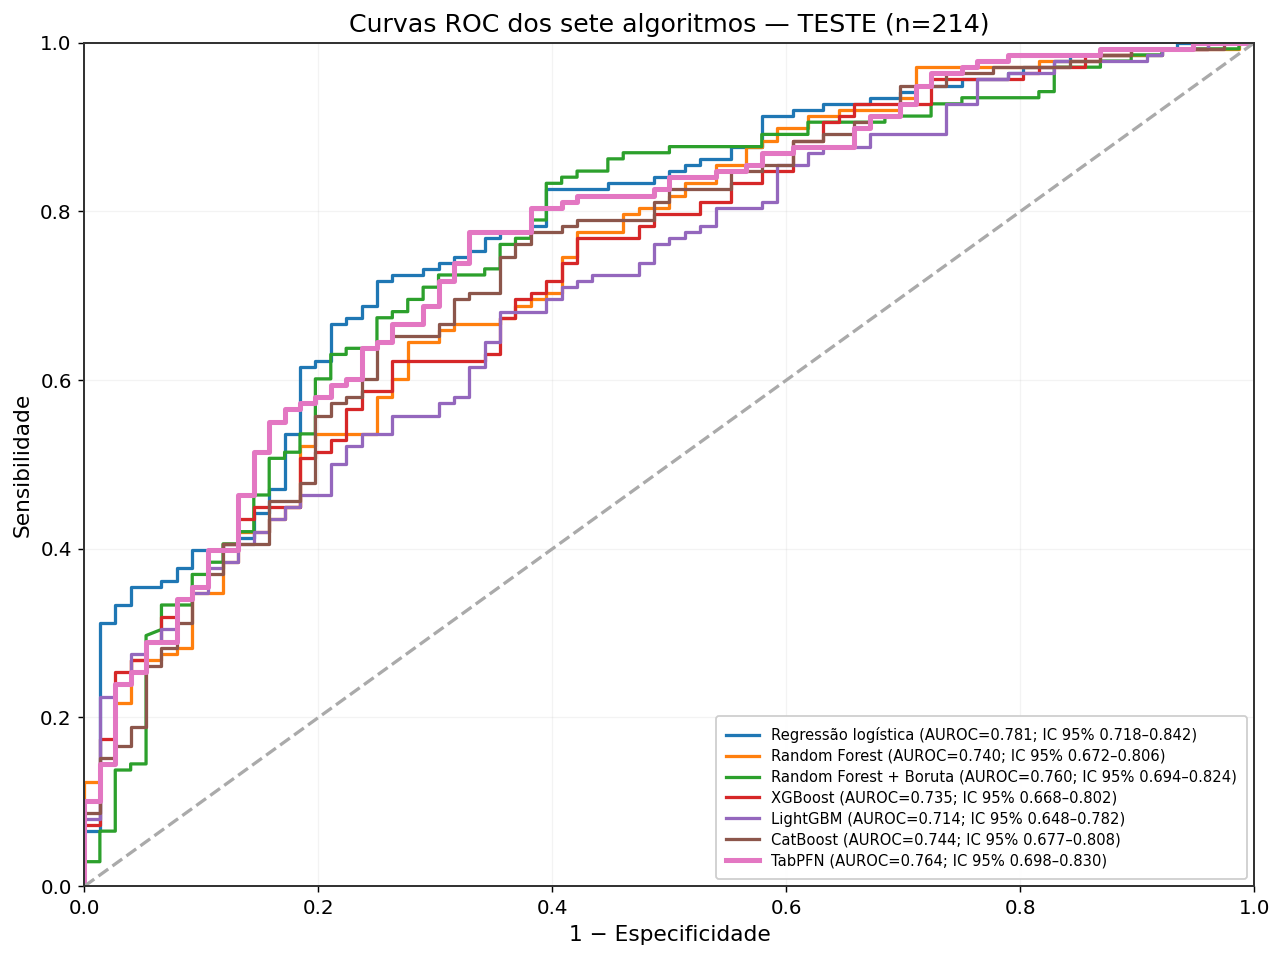


[7B] FIGURA GERADA COM SUCESSO
[7B] PNG: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/metricas_teste/Figura_ROC_estilo_original_AUROC_IC95.png
[7B] PDF: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/metricas_teste/Figura_ROC_estilo_original_AUROC_IC95.pdf
[7B] Sete modelos com AUROC e IC 95%.
[7B] Nenhum treinamento realizado.


In [ ]:

# ================================================================
# BLOCO 7B — CURVAS ROC DOS SETE ALGORITMOS
# ANALISE PRINCIPAL — CONJUNTO INDEPENDENTE DE TESTE
#
# Estilo igual ao grafico ROC original:
# - Titulo superior
# - Quatro bordas visiveis
# - Sete curvas com as cores originais
# - Legenda no canto inferior direito
# - AUROC e respectivos IC 95%
#
# Executa sozinho em uma nova sessao do Google Colab.
# Nao treina, nao otimiza e nao recalcula bootstrap.
# ================================================================

import os
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score
from google.colab import drive

# ================================================================
# 1. MONTAR GOOGLE DRIVE
# ================================================================

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

# ================================================================
# 2. LOCALIZAR OS RESULTADOS DA ANALISE PRINCIPAL
# ================================================================

DIR_METRICAS_7B = (
    "/content/drive/MyDrive/Gitrub/"
    "resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/"
    "execucoes/20261031_001033_d5dd674c/"
    "metricas_teste"
)

ARQUIVO_PROB = os.path.join(
    DIR_METRICAS_7B,
    "probabilidades_sete_modelos.joblib"
)

ARQUIVO_IC = os.path.join(
    DIR_METRICAS_7B,
    "ic95_bootstrap_sete_modelos_teste.csv"
)

for arquivo in [ARQUIVO_PROB, ARQUIVO_IC]:
    if not os.path.isfile(arquivo):
        raise FileNotFoundError(
            f"Arquivo nao encontrado no Google Drive:\n{arquivo}"
        )

print("[7B] Arquivos localizados.", flush=True)

# ================================================================
# 3. CARREGAR PROBABILIDADES E INTERVALOS DE CONFIANCA
# ================================================================

dados = joblib.load(ARQUIVO_PROB)

if not isinstance(dados, dict):
    raise TypeError(
        "O arquivo de probabilidades nao contem um dicionario."
    )

for chave in ["y_teste", "p_teste"]:
    if chave not in dados:
        raise KeyError(
            f"Chave '{chave}' ausente. "
            f"Chaves disponiveis: {list(dados.keys())}"
        )

y_teste = np.asarray(
    dados["y_teste"], dtype=int
).ravel()

probabilidades = dados["p_teste"]

tabela_ic = pd.read_csv(ARQUIVO_IC)

colunas_necessarias = [
    "modelo",
    "metrica",
    "estimativa_teste",
    "IC95_inferior",
    "IC95_superior"
]

faltando = [
    coluna
    for coluna in colunas_necessarias
    if coluna not in tabela_ic.columns
]

if faltando:
    raise KeyError(
        "Colunas ausentes no CSV de IC 95%: "
        + ", ".join(faltando)
        + "\nColunas encontradas: "
        + ", ".join(tabela_ic.columns)
    )

ic_auc = (
    tabela_ic.loc[
        tabela_ic["metrica"].astype(str).str.upper()
        == "AUROC"
    ]
    .set_index("modelo")
)

# ================================================================
# 4. DEFINIR OS SETE MODELOS E AS CORES ORIGINAIS
# ================================================================

modelos = [
    "Regressão logística",
    "Random Forest",
    "Random Forest + Boruta",
    "XGBoost",
    "LightGBM",
    "CatBoost",
    "TabPFN"
]

cores = {
    "Regressão logística": "#1f77b4",
    "Random Forest": "#ff7f0e",
    "Random Forest + Boruta": "#2ca02c",
    "XGBoost": "#d62728",
    "LightGBM": "#9467bd",
    "CatBoost": "#8c564b",
    "TabPFN": "#e377c2"
}

# ================================================================
# 5. CONFERIR A INTEGRIDADE DOS RESULTADOS
# ================================================================

if len(y_teste) != 214:
    raise ValueError(
        f"Esperados 214 pacientes no teste, "
        f"encontrados {len(y_teste)}."
    )

if set(np.unique(y_teste)) != {0, 1}:
    raise ValueError(
        "O conjunto de teste deve conter as classes 0 e 1."
    )

for nome in modelos:

    if nome not in probabilidades:
        raise KeyError(
            f"Probabilidades ausentes para {nome}. "
            f"Modelos encontrados: {list(probabilidades.keys())}"
        )

    if nome not in ic_auc.index:
        raise KeyError(
            f"IC 95% ausente para {nome}. "
            f"Modelos encontrados: {list(ic_auc.index)}"
        )

print("[7B] Resultados dos sete modelos conferidos.", flush=True)

# ================================================================
# 6. CONFIGURACAO VISUAL DA FIGURA ORIGINAL
# ================================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 9
})

fig, ax = plt.subplots(
    figsize=(10, 7.5),
    dpi=130
)

# ================================================================
# 7. DESENHAR AS CURVAS COM AUROC E IC 95%
# ================================================================

for nome in modelos:

    p = np.asarray(
        probabilidades[nome],
        dtype=float
    ).ravel()

    if len(p) != len(y_teste):
        raise ValueError(
            f"{nome}: quantidade incorreta de probabilidades."
        )

    if not np.all(np.isfinite(p)):
        raise ValueError(
            f"{nome}: probabilidades nao finitas."
        )

    if np.any((p < 0) | (p > 1)):
        raise ValueError(
            f"{nome}: probabilidades fora do intervalo [0, 1]."
        )

    fpr, tpr, _ = roc_curve(y_teste, p)

    auroc = roc_auc_score(y_teste, p)

    resultado = ic_auc.loc[nome]

    auroc_salva = float(
        resultado["estimativa_teste"]
    )

    ic_inferior = float(
        resultado["IC95_inferior"]
    )

    ic_superior = float(
        resultado["IC95_superior"]
    )

    if not np.isclose(
        auroc,
        auroc_salva,
        atol=1e-5
    ):
        raise RuntimeError(
            f"AUROC divergente em {nome}: "
            f"calculada={auroc:.6f}; "
            f"salva={auroc_salva:.6f}"
        )

    if not (
        np.isfinite(ic_inferior)
        and np.isfinite(ic_superior)
        and ic_inferior <= auroc <= ic_superior
    ):
        raise RuntimeError(
            f"Intervalo de confianca invalido para {nome}."
        )

    # MESMO ESTILO DA LEGENDA ORIGINAL,
    # ACRESCENTANDO O INTERVALO DE CONFIANCA

    legenda = (
        f"{nome} "
        f"(AUROC={auroc:.3f}; "
        f"IC 95% {ic_inferior:.3f}–{ic_superior:.3f})"
    )

    ax.plot(
        fpr,
        tpr,
        color=cores[nome],
        linewidth=2.8 if nome == "TabPFN" else 1.8,
        label=legenda
    )

    print(
        f"{nome}: AUROC={auroc:.3f} "
        f"(IC 95% {ic_inferior:.3f}–{ic_superior:.3f})"
    )

# ================================================================
# 8. LINHA DIAGONAL DO ACASO
# ================================================================

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="#aaaaaa",
    linewidth=1.8,
    label="_nolegend_"
)

# ================================================================
# 9. EIXOS, TITULO E QUATRO BORDAS
# ================================================================

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_xticks(
    np.arange(0, 1.01, 0.2)
)

ax.set_yticks(
    np.arange(0, 1.01, 0.2)
)

ax.set_xlabel(
    "1 − Especificidade"
)

ax.set_ylabel(
    "Sensibilidade"
)

ax.set_title(
    "Curvas ROC dos sete algoritmos — TESTE (n=214)"
)

ax.grid(
    True,
    alpha=0.15,
    linewidth=0.7
)

# MANTER AS QUATRO BORDAS, COMO NA FIGURA ORIGINAL
for lado in ["top", "right", "bottom", "left"]:

    ax.spines[lado].set_visible(True)
    ax.spines[lado].set_color("#333333")
    ax.spines[lado].set_linewidth(1.1)

# ================================================================
# 10. LEGENDA DENTRO DO GRAFICO — CANTO INFERIOR DIREITO
# ================================================================

ax.legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc",
    framealpha=0.95,
    fontsize=8.2,
    borderpad=0.7,
    labelspacing=0.40,
    handlelength=2.2
)

fig.tight_layout()

# ================================================================
# 11. SALVAR FIGURA EM PNG E PDF
# ================================================================

CAMINHO_PNG = os.path.join(
    DIR_METRICAS_7B,
    "Figura_ROC_estilo_original_AUROC_IC95.png"
)

CAMINHO_PDF = os.path.join(
    DIR_METRICAS_7B,
    "Figura_ROC_estilo_original_AUROC_IC95.pdf"
)

fig.savefig(
    CAMINHO_PNG,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    CAMINHO_PDF,
    bbox_inches="tight",
    facecolor="white"
)

# ================================================================
# 12. EXIBIR FIGURA NO COLAB
# ================================================================

plt.show()
plt.close(fig)

print()
print("[7B] FIGURA GERADA COM SUCESSO")
print("[7B] PNG:", CAMINHO_PNG)
print("[7B] PDF:", CAMINHO_PDF)
print("[7B] Sete modelos com AUROC e IC 95%.")
print("[7B] Nenhum treinamento realizado.")


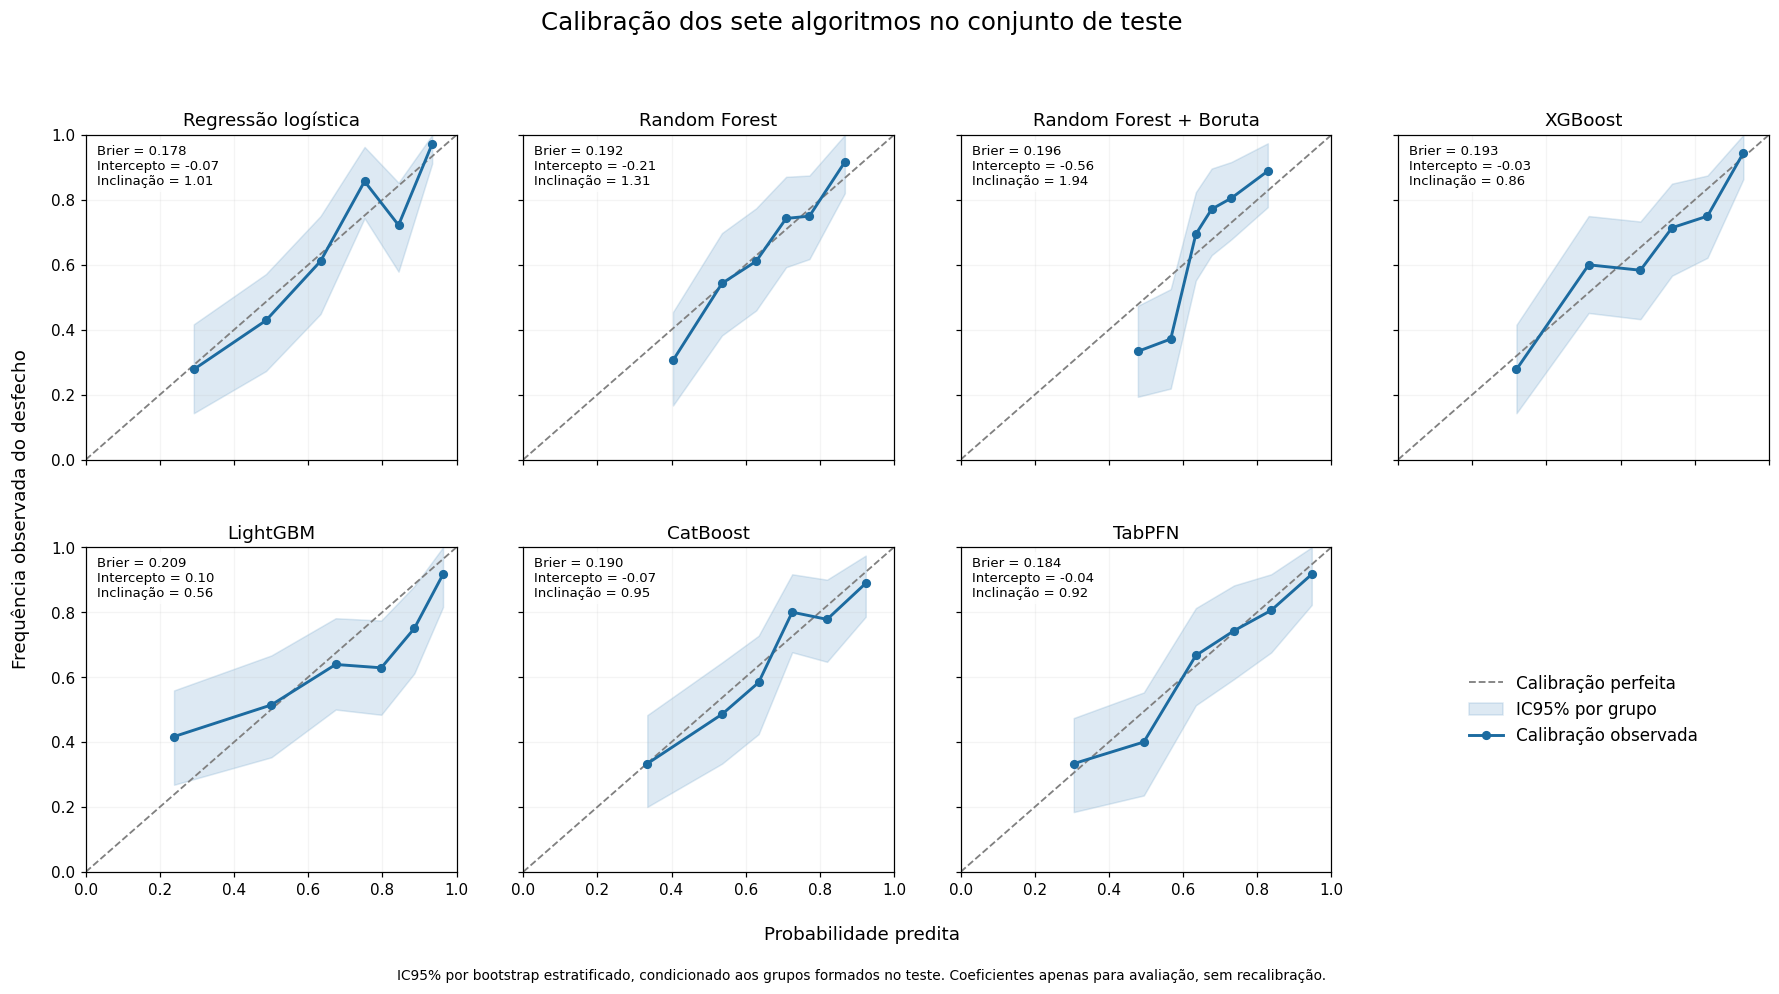

[7C] Calibracao descritiva (sem ajuste de probabilidades):


,modelo,n_teste,n_grupos,Brier,intercepto_calibracao,inclinacao_calibracao
0,Regressão logística,214,6,0.1778,-0.0735,1.0082
1,Random Forest,214,6,0.1924,-0.2101,1.3091
2,Random Forest + Boruta,214,6,0.1956,-0.5574,1.9403
3,XGBoost,214,6,0.1930,-0.0324,0.8621
4,LightGBM,214,6,0.2086,0.1039,0.5617
5,CatBoost,214,6,0.1896,-0.0701,0.9545
6,TabPFN,214,6,0.1835,-0.0413,0.9187


[7C] Figuras salvas em: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/metricas_teste/curvas_calibracao_sete_algoritmos_teste.png e /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/metricas_teste/curvas_calibracao_sete_algoritmos_teste.pdf


In [ ]:
# =============================================================================
# BLOCO 7C — CURVAS DE CALIBRACAO DOS SETE ALGORITMOS (TESTE)
# =============================================================================
# Requer BLOCO 1 e 7A. Avalia; NAO recalibra nem reestima os modelos.
# Figura em sete paineis: proporcao observada x probabilidade media predita.
# IC95% por reamostragem estratificada dentro do teste, condicional aos bins.
# Intercepto e inclinacao: regressao logistica de y em logit(p) no teste.
# Esses coeficientes sao descritivos: NAO sao usados para alterar preditores.
# =============================================================================

_requeridos_7c = ['os', 'np', 'pd', 'plt', 'joblib', 'DIR_METRICAS',
                  'brier_score_loss', 'LogisticRegression']
_ausentes_7c = [chave for chave in _requeridos_7c if chave not in globals()]
if _ausentes_7c:
    raise RuntimeError('Execute o Bloco 1 antes do 7C. Ausentes: ' + ', '.join(_ausentes_7c))

_arquivo_7c = os.path.join(DIR_METRICAS, 'probabilidades_sete_modelos.joblib')
if not os.path.isfile(_arquivo_7c):
    raise FileNotFoundError('Execute o Bloco 7A corrigido antes do 7C: ' + _arquivo_7c)
_dados_7c = joblib.load(_arquivo_7c)
_y_7c = np.asarray(_dados_7c['y_teste']).ravel().astype(int)
_nomes_7c = list(_dados_7c['modelos'])
_probs_7c = _dados_7c['p_teste']
if len(_nomes_7c) != 7 or len(set(_nomes_7c)) != 7 or set(_probs_7c) != set(_nomes_7c):
    raise ValueError('O arquivo do 7A deve conter sete modelos.')
if not np.array_equal(np.unique(_y_7c), [0, 1]):
    raise ValueError('A calibracao exige ambas as classes no teste.')

# Com teste relativamente pequeno, 6 grupos quantilicos permitem visualizar
# a tendencia sem fragmentar excessivamente os eventos. Grupos sao calculados
# separadamente para cada modelo; podem ter tamanhos diferentes por empates.
_N_GRUPOS_7c = 6
_N_BOOT_7c = 1000
_SEED_7c = int(globals().get('SEED', 42)) + 7003
_rng_7c = np.random.default_rng(_SEED_7c)
_idx0_7c = np.flatnonzero(_y_7c == 0)
_idx1_7c = np.flatnonzero(_y_7c == 1)
_indices_boot_7c = [np.concatenate([
    _rng_7c.choice(_idx0_7c, size=len(_idx0_7c), replace=True),
    _rng_7c.choice(_idx1_7c, size=len(_idx1_7c), replace=True)
]) for _ in range(_N_BOOT_7c)]

_rotulos_7c = {'RL': 'Regressão logística', 'LR': 'Regressão logística',
               'RF': 'Random Forest', 'RF+Boruta': 'Random Forest + Boruta',
               'RF_BORUTA': 'Random Forest + Boruta',
               'XGB': 'XGBoost', 'LGB': 'LightGBM', 'LGBM': 'LightGBM',
               'CAT': 'CatBoost', 'TABPFN': 'TabPFN'}

_fig_7c, _eixos_7c = plt.subplots(2, 4, figsize=(17, 8.7), sharex=True, sharey=True)
_fig_7c.suptitle('Calibração dos sete algoritmos no conjunto de teste', fontsize=16, y=1.02)
_linhas_7c = []
for _i_7c, _nome_7c in enumerate(_nomes_7c):
    _ax_7c = _eixos_7c.flat[_i_7c]
    _p_7c = np.asarray(_probs_7c[_nome_7c], dtype=float).ravel()
    if len(_p_7c) != len(_y_7c) or not np.isfinite(_p_7c).all() or np.any((_p_7c < 0) | (_p_7c > 1)):
        raise ValueError('Probabilidades invalidas para ' + _nome_7c)

    # Grupos aproximados por quantis de probabilidade, evitando bordas duplicadas.
    _bordas_7c = np.unique(np.quantile(_p_7c, np.linspace(0, 1, _N_GRUPOS_7c + 1)))
    if len(_bordas_7c) < 3:
        # Probabilidade quase constante: unico grupo (calibracao pouco informativa).
        _grupos_7c = np.zeros(len(_p_7c), dtype=int)
    else:
        _grupos_7c = np.searchsorted(_bordas_7c[1:-1], _p_7c, side='right')
    _g_7c = np.unique(_grupos_7c)
    _x_7c, _obs_7c, _li_7c, _ls_7c = [], [], [], []
    for _g_atual_7c in _g_7c:
        _mascara_7c = (_grupos_7c == _g_atual_7c)
        _x_7c.append(float(np.mean(_p_7c[_mascara_7c])))
        _obs_7c.append(float(np.mean(_y_7c[_mascara_7c])))
        _valores_7c = []
        for _idx_7c in _indices_boot_7c:
            _m_7c = _mascara_7c[_idx_7c]
            if np.any(_m_7c):
                _valores_7c.append(float(np.mean(_y_7c[_idx_7c][_m_7c])))
        if len(_valores_7c) >= 100:
            _a_7c, _b_7c = np.percentile(_valores_7c, [2.5, 97.5])
        else:
            _a_7c, _b_7c = np.nan, np.nan
        _li_7c.append(_a_7c)
        _ls_7c.append(_b_7c)

    _x_7c = np.array(_x_7c)
    _obs_7c = np.array(_obs_7c)
    _li_7c = np.array(_li_7c)
    _ls_7c = np.array(_ls_7c)
    _ax_7c.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.2,
                label='Calibração perfeita')
    _ax_7c.fill_between(_x_7c, _li_7c, _ls_7c,
                         color='#3B82B8', alpha=.17, label='IC95% por grupo')
    _ax_7c.plot(_x_7c, _obs_7c, color='#1C6BA0', marker='o', lw=1.9,
                markersize=5, label='Calibração observada')

    _brier_7c = float(brier_score_loss(_y_7c, _p_7c))
    _intercepto_7c, _inclinacao_7c = np.nan, np.nan
    try:
        _logit_7c = np.log(np.clip(_p_7c, 1e-6, 1 - 1e-6) /
                           (1 - np.clip(_p_7c, 1e-6, 1 - 1e-6))).reshape(-1, 1)
        if np.std(_logit_7c) > 1e-10:
            # Sem penalizacao, para estimar intercepto e inclinacao de calibracao.
            _reg_7c = LogisticRegression(penalty=None, solver='lbfgs', max_iter=1500)
            _reg_7c.fit(_logit_7c, _y_7c)
            _intercepto_7c = float(_reg_7c.intercept_[0])
            _inclinacao_7c = float(_reg_7c.coef_[0, 0])
    except Exception as _erro_7c:
        print(f'[7C] Coeficientes de calibracao indisponiveis para {_nome_7c}: {_erro_7c}')

    _ax_7c.set(title=_rotulos_7c.get(_nome_7c, _nome_7c), xlim=(0, 1), ylim=(0, 1))
    _ax_7c.grid(alpha=.13)
    _ax_7c.text(.03, .97,
                f'Brier = {_brier_7c:.3f}\nIntercepto = {_intercepto_7c:.2f}\nInclinação = {_inclinacao_7c:.2f}',
                fontsize=8.7, ha='left', va='top', transform=_ax_7c.transAxes,
                bbox=dict(facecolor='white', alpha=.8, edgecolor='none', pad=3))
    _linhas_7c.append({'modelo': _nome_7c, 'n_teste': len(_y_7c),
                       'n_grupos': len(_g_7c), 'Brier': _brier_7c,
                       'intercepto_calibracao': _intercepto_7c,
                       'inclinacao_calibracao': _inclinacao_7c})

_eixos_7c.flat[7].axis('off')
_eixos_7c.flat[7].legend(*_eixos_7c.flat[0].get_legend_handles_labels(),
                        loc='center', frameon=False, fontsize=11)
_fig_7c.supxlabel('Probabilidade predita', y=.045)
_fig_7c.supylabel('Frequência observada do desfecho', x=.045)
_fig_7c.text(.5, .007,
             'IC95% por bootstrap estratificado, condicionado aos grupos formados no teste. '
             'Coeficientes apenas para avaliação, sem recalibração.',
             ha='center', fontsize=9)
_fig_7c.subplots_adjust(wspace=.18, hspace=.27, top=.89, bottom=.12, left=.085, right=.985)

_caminho_png_7c = os.path.join(DIR_METRICAS, 'curvas_calibracao_sete_algoritmos_teste.png')
_caminho_pdf_7c = os.path.join(DIR_METRICAS, 'curvas_calibracao_sete_algoritmos_teste.pdf')
_fig_7c.savefig(_caminho_png_7c, dpi=320, bbox_inches='tight', facecolor='white')
_fig_7c.savefig(_caminho_pdf_7c, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(_fig_7c)

tabela_calibracao_7c = pd.DataFrame(_linhas_7c)
_caminho_tabela_7c = os.path.join(DIR_METRICAS, 'metricas_calibracao_sete_algoritmos.csv')
if 'gravar_csv_atomico' in globals():
    gravar_csv_atomico(tabela_calibracao_7c, _caminho_tabela_7c)
else:
    tabela_calibracao_7c.to_csv(_caminho_tabela_7c, index=False)
print('[7C] Calibracao descritiva (sem ajuste de probabilidades):')
display(tabela_calibracao_7c.round(4))
print('[7C] Figuras salvas em:', _caminho_png_7c, 'e', _caminho_pdf_7c)


In [ ]:
# ============================================================
# CONSULTA — VARIÁVEIS DO RANDOM FOREST + BORUTA FINAL
# Não executa treinamento nem otimização
# ============================================================

nome = "Random Forest + Boruta"

# Recupera o pipeline final já ajustado
modelo_boruta = modelos_finais[nome]

# Acessa a etapa de seleção do pipeline
print("Etapas do pipeline:", list(modelo_boruta.named_steps))

seletor = next(
    etapa for etapa in modelo_boruta.named_steps.values()
    if hasattr(etapa, "selecionadas_")
)

tabela_boruta_final = pd.DataFrame({
    "variavel": seletor.selecionadas_,
    "classificacao": [
        "Confirmada" if v in seletor.confirmadas_
        else "Tentativa" if v in seletor.tentativas_
        else "Seleção alternativa"
        for v in seletor.selecionadas_
    ]
})

display(tabela_boruta_final)

# Salvar no Google Drive
destino = os.path.join(
    DIR_MODELOS,
    "variaveis_selecionadas_boruta_final.csv"
)

gravar_csv_atomico(tabela_boruta_final, destino)

print("Tabela salva em:", destino)

Etapas do pipeline: ['prep', 'boruta', 'clf']


,variavel,classificacao
0,IDADE,Confirmada
1,TEMPO_DE_SINTOMAS,Confirmada
2,INSUF_MI_AO_MOD_GRAVE,Confirmada
3,HB_D0,Confirmada
4,LEUCO_D0,Confirmada
5,LINFOCITOS_D0,Confirmada
6,PLAQUETAS_D0,Confirmada
7,CREAT_D0,Confirmada
8,VEG_10MM,Confirmada
9,COMPLIC_PERIVALVAR_ADM,Confirmada


Tabela salva em: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/modelos_finais/variaveis_selecionadas_boruta_final.csv


In [ ]:
# ============================================================
# RECUPERAR Xtr E Xte PARA O SHAP
# Sem treinamento, Optuna ou nova divisão aleatória
# ============================================================

import json
import os
import numpy as np

arquivo = os.path.join(DIR_EXECUCAO, "identidade_execucao.json")

if not os.path.isfile(arquivo):
    raise FileNotFoundError(
        f"Arquivo da divisão original não encontrado: {arquivo}"
    )

with open(arquivo, "r", encoding="utf-8") as f:
    identidade = json.load(f)

# Recuperar os índices EXATOS da execução original
idx_tr = np.asarray(identidade["indices_treino"], dtype=int)
idx_te = np.asarray(identidade["indices_teste"], dtype=int)

# Conferir as colunas antes de recuperar os dados
if list(X_df.columns) != identidade["colunas"]:
    raise RuntimeError(
        "As colunas da base não correspondem à execução original."
    )

# Recuperar os mesmos pacientes
Xtr = X_df.iloc[idx_tr].reset_index(drop=True)
Xte = X_df.iloc[idx_te].reset_index(drop=True)

if Xtr.shape[0] != 497 or Xte.shape[0] != 214:
    raise RuntimeError(
        f"Divisão inesperada: treino={len(Xtr)}, teste={len(Xte)}"
    )

print("Divisão original recuperada com sucesso!")
print("Treinamento:", Xtr.shape)
print("Teste:", Xte.shape)
print("Execução:", DIR_EXECUCAO)

Divisão original recuperada com sucesso!
Treinamento: (497, 29)
Teste: (214, 29)
Execução: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c


[7D] SHAP: 0.54.1
[7D] Arquivos originais encontrados.
[7D] Treino: (497, 29)
[7D] Teste: (214, 29)
[7D] Regressao logistica recuperada e validada.
[7D] Calculando explicacoes SHAP...
[7D] SHAP calculado e salvo.


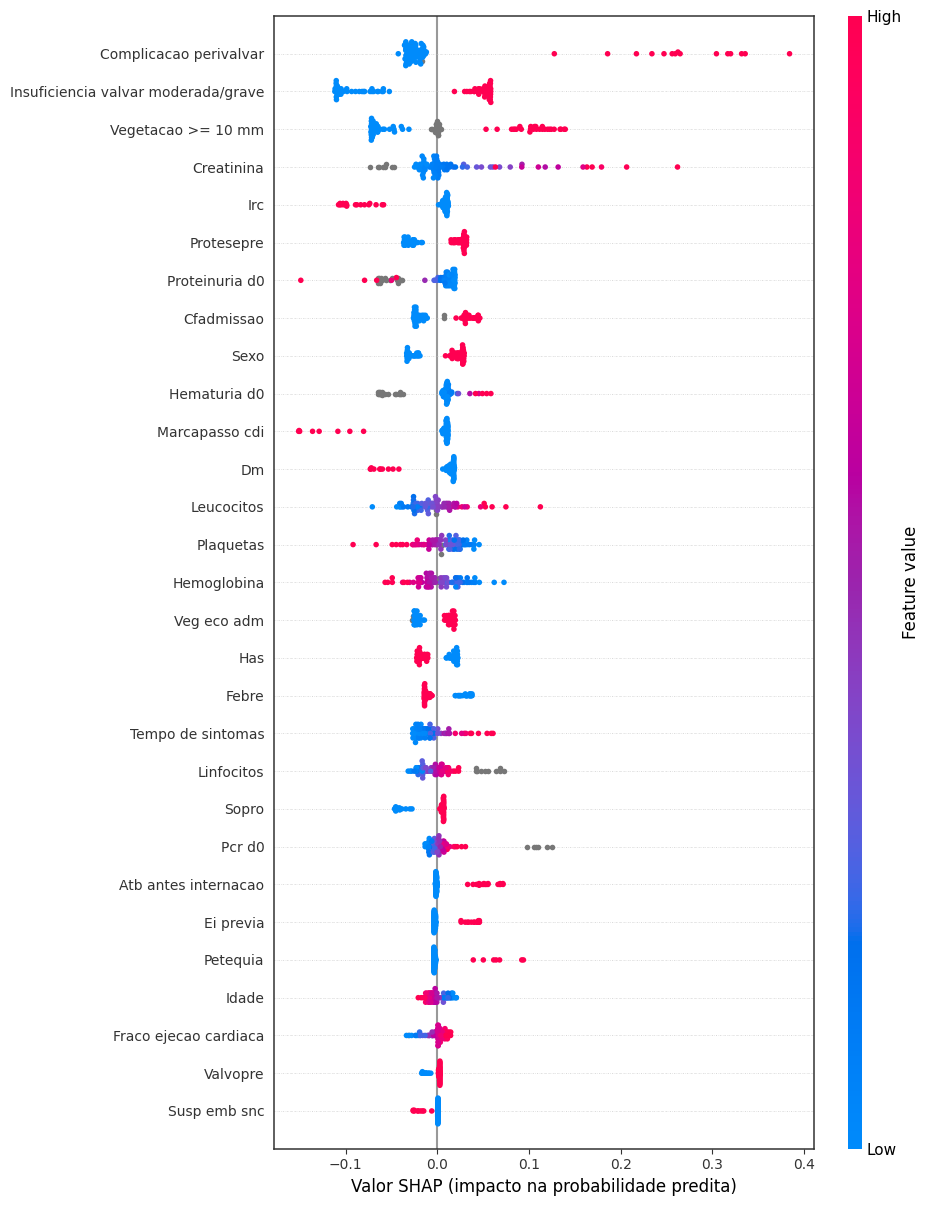


[7D] SHAP GERADO COM SUCESSO
[7D] Modelo: regressao logistica
[7D] Pacientes explicados: 80
[7D] Preditores exibidos: 29
[7D] PNG: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/shap/SHAP_Logistica_Beeswarm_4_Bordas.png
[7D] PDF: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/shap/SHAP_Logistica_Beeswarm_4_Bordas.pdf
[7D] Nenhum treinamento executado.


In [ ]:

# ================================================================
# BLOCO 7D — SHAP BEESWARM DA REGRESSAO LOGISTICA
# ANALISE PRINCIPAL | VERSAO COMPLETA CORRIGIDA
#
# - Independente dos blocos anteriores
# - Recupera dados e divisao original do Google Drive
# - Carrega o modelo treinado, sem reajuste
# - Corrige a classe PreProcessador
# - Calcula SHAP sobre probabilidade da classe positiva
# - Mostra todos os preditores individualmente
# - Quatro bordas visiveis
# - Salva PNG e PDF no Drive
# ================================================================

import os
import re
import sys
import json
import joblib
import subprocess
import importlib.util
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted
from google.colab import drive

# ================================================================
# 1. INSTALAR E IMPORTAR O SHAP
# ================================================================

if importlib.util.find_spec("shap") is None:
    subprocess.check_call([
        sys.executable,
        "-m", "pip",
        "install", "-q", "shap"
    ])

import shap

print("[7D] SHAP:", shap.__version__, flush=True)

# ================================================================
# 2. MONTAR O GOOGLE DRIVE
# ================================================================

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

RAIZ = "/content/drive/MyDrive/Gitrub"

ID_EXECUCAO = "20261031_001033_d5dd674c"

DIR_EXECUCAO = os.path.join(
    RAIZ,
    "resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026",
    "execucoes",
    ID_EXECUCAO
)

DIR_MODELOS = os.path.join(
    DIR_EXECUCAO,
    "modelos_finais"
)

DIR_SHAP = os.path.join(
    DIR_EXECUCAO,
    "shap"
)

os.makedirs(DIR_SHAP, exist_ok=True)

ARQ_BASE = os.path.join(
    RAIZ,
    "base_modelagem_necessidade_cirurgia.xlsx"
)

ARQ_IDENTIDADE = os.path.join(
    DIR_EXECUCAO,
    "identidade_execucao.json"
)

ARQ_MODELO = os.path.join(
    DIR_MODELOS,
    "modelo_final_v1_logistica.joblib"
)

for caminho in [
    ARQ_BASE,
    ARQ_IDENTIDADE,
    ARQ_MODELO
]:
    if not os.path.isfile(caminho):
        raise FileNotFoundError(
            "Arquivo nao encontrado:\n" + caminho
        )

print("[7D] Arquivos originais encontrados.", flush=True)

# ================================================================
# 3. CLASSE ORIGINAL DO PRE-PROCESSADOR
#
# IMPORTANTE:
# A definicao precisa existir para recuperar o Pipeline
# salvo com joblib.
#
# O metodo fit existe, mas NAO sera executado nesta celula.
# ================================================================

class PreProcessador(BaseEstimator, TransformerMixin):

    def __init__(self, max_missing=0.70, ind_missing=0.05):
        self.max_missing = max_missing
        self.ind_missing = ind_missing

    def _validar_entrada(self, X):

        if not isinstance(X, pd.DataFrame):
            raise TypeError(
                "PreProcessador requer DataFrame."
            )

        if not X.columns.is_unique:
            raise ValueError(
                "Existem nomes de colunas duplicados."
            )

        if X.empty:
            raise ValueError(
                "DataFrame de entrada vazio."
            )

        nao_numericas = X.select_dtypes(
            exclude="number"
        ).columns.tolist()

        if nao_numericas:
            X = X.copy()

            for coluna in nao_numericas:
                try:
                    X[coluna] = pd.to_numeric(
                        X[coluna],
                        errors="raise"
                    ).astype(float)

                except (TypeError, ValueError) as exc:
                    raise TypeError(
                        f"Preditor nao numerico: {coluna}"
                    ) from exc

        return X

    def fit(self, X, y=None):

        X = self._validar_entrada(X)

        if not (
            0 <= self.max_missing < 1
            and 0 <= self.ind_missing <= 1
        ):
            raise ValueError(
                "Parametros de ausencia invalidos."
            )

        if np.isinf(
            X.to_numpy(dtype=float)
        ).any():
            raise ValueError(
                "Existem valores infinitos."
            )

        frac = X.isna().mean()

        constante = (
            X.nunique(dropna=True) <= 1
        )

        conservar = (
            (frac <= self.max_missing)
            & (~constante)
        )

        self.colunas_ = X.columns[
            conservar
        ].tolist()

        self.descartadas_ = X.columns[
            ~conservar
        ].tolist()

        if not self.colunas_:
            raise ValueError(
                "Nenhuma variavel foi retida."
            )

        self.indicadores_ = [
            c for c in self.colunas_
            if frac[c] >= self.ind_missing
            and frac[c] > 0
        ]

        self.medianas_ = X[
            self.colunas_
        ].median()

        if self.medianas_.isna().any():
            raise ValueError(
                "Mediana invalida."
            )

        self.nomes_ = (
            self.colunas_
            + [
                f"{c}__ausente"
                for c in self.indicadores_
            ]
        )

        if len(self.nomes_) != len(set(self.nomes_)):
            raise ValueError(
                "Nomes de variaveis duplicados."
            )

        self.feature_names_in_ = np.asarray(
            X.columns,
            dtype=object
        )

        self.n_features_in_ = X.shape[1]

        return self

    def transform(self, X):

        check_is_fitted(
            self,
            ["colunas_", "medianas_", "nomes_"]
        )

        X = self._validar_entrada(X)

        ausentes = [
            c for c in self.colunas_
            if c not in X.columns
        ]

        if ausentes:
            raise ValueError(
                "Colunas ausentes: "
                + ", ".join(ausentes)
            )

        Z = X.loc[
            :, self.colunas_
        ].copy()

        indicadores = {
            f"{c}__ausente": (
                Z[c].isna().astype(float)
            )
            for c in self.indicadores_
        }

        Z = Z.fillna(self.medianas_)

        if indicadores:
            Z = pd.concat(
                [
                    Z,
                    pd.DataFrame(
                        indicadores,
                        index=Z.index
                    )
                ],
                axis=1
            )

        Z = Z.loc[
            :, self.nomes_
        ].astype(float)

        if not np.isfinite(
            Z.to_numpy()
        ).all():
            raise ValueError(
                "Pre-processamento gerou valores invalidos."
            )

        return Z

    def get_feature_names_out(
        self, input_features=None
    ):

        check_is_fitted(
            self,
            "nomes_"
        )

        return np.asarray(
            self.nomes_,
            dtype=object
        )

# ================================================================
# 4. RECUPERAR A BASE ORIGINAL
# ================================================================

def sem_acento(texto):

    texto = unicodedata.normalize(
        "NFKD",
        str(texto)
    )

    texto = "".join(
        c for c in texto
        if not unicodedata.combining(c)
    )

    texto = re.sub(
        r"[^0-9a-zA-Z_]+",
        "_",
        texto
    )

    return re.sub(
        r"_+",
        "_",
        texto
    ).strip("_")


base = pd.read_excel(
    ARQ_BASE
).rename(
    columns=lambda c: sem_acento(c)
)

base = (
    base.sort_values("ID_REGISTRO")
    .reset_index(drop=True)
)

if base["ID_REGISTRO"].duplicated().any():
    raise RuntimeError(
        "IDs duplicados na base."
    )

LIMITES = {
    "IDADE": (0, 110),
    "CREAT_D0": (0, 30),
    "HB_D0": (2, 25),
    "LEUCO_D0": (0, 100000),
    "PLAQUETAS_D0": (0, 2000000),
    "FRACO_EJECAO_CARDIACA": (5, 90),
    "TEMPO_DE_SINTOMAS": (0, 730)
}

for coluna, (minimo, maximo) in LIMITES.items():

    if coluna in base.columns:

        valores = pd.to_numeric(
            base[coluna],
            errors="coerce"
        )

        invalido = (
            (valores < minimo)
            | (valores > maximo)
        )

        base.loc[
            invalido,
            coluna
        ] = np.nan

coorte = (
    base.loc[
        base["INDICACAO_CIRURGICA"].notna()
    ]
    .reset_index(drop=True)
)

excluir = [
    "ID_REGISTRO",
    "INDICACAO_CIRURGICA",
    "MITRAL",
    "AORTICA",
    "LADO_DIREITO",
    "IRAS_ALGUMA"
]

X_df = coorte.drop(
    columns=[
        c for c in excluir
        if c in coorte.columns
    ]
)

# ================================================================
# 5. RECUPERAR OS INDICES ORIGINAIS
# ================================================================

with open(
    ARQ_IDENTIDADE,
    "r",
    encoding="utf-8"
) as f:
    identidade = json.load(f)

if list(X_df.columns) != identidade["colunas"]:
    raise RuntimeError(
        "As colunas diferem da execucao original."
    )

idx_treino = np.asarray(
    identidade["indices_treino"],
    dtype=int
)

idx_teste = np.asarray(
    identidade["indices_teste"],
    dtype=int
)

Xtr = (
    X_df.iloc[idx_treino]
    .reset_index(drop=True)
)

Xte = (
    X_df.iloc[idx_teste]
    .reset_index(drop=True)
)

if Xtr.shape != (497, 29):
    raise RuntimeError(
        f"Treino inesperado: {Xtr.shape}"
    )

if Xte.shape != (214, 29):
    raise RuntimeError(
        f"Teste inesperado: {Xte.shape}"
    )

print("[7D] Treino:", Xtr.shape)
print("[7D] Teste:", Xte.shape)

# ================================================================
# 6. CARREGAR A REGRESSAO LOGISTICA JA TREINADA
# ================================================================

modelo = joblib.load(ARQ_MODELO)

if not hasattr(modelo, "predict_proba"):
    raise RuntimeError(
        "O modelo salvo nao implementa predict_proba."
    )

colunas = list(Xtr.columns)

if hasattr(modelo, "feature_names_in_"):
    if list(modelo.feature_names_in_) != colunas:
        raise RuntimeError(
            "Ordem de preditores diferente da original."
        )

# Testar o pipeline ANTES de calcular SHAP.
teste_previsao = modelo.predict_proba(
    Xte.iloc[:3]
)

if teste_previsao.shape != (3, 2):
    raise RuntimeError(
        "Saida inesperada do modelo."
    )

print(
    "[7D] Regressao logistica recuperada e validada.",
    flush=True
)

# ================================================================
# 7. SELECIONAR AMOSTRAS PARA EXPLICACAO
# ================================================================

SEED = 1707

N_FUNDO = min(30, len(Xtr))
N_EXPLICAR = min(80, len(Xte))

fundo = Xtr.sample(
    n=N_FUNDO,
    random_state=SEED
).copy()

amostra = Xte.sample(
    n=N_EXPLICAR,
    random_state=SEED + 1
).copy()

# ================================================================
# 8. FUNCAO DE PREDICAO PARA O SHAP
# ================================================================

def prever_classe_positiva(matriz):

    dados_entrada = pd.DataFrame(
        np.asarray(matriz),
        columns=colunas
    )

    probabilidades = modelo.predict_proba(
        dados_entrada
    )

    classes = np.asarray(
        modelo.classes_
    )

    posicoes = np.where(
        classes == 1
    )[0]

    if len(posicoes) != 1:
        raise RuntimeError(
            "Classe positiva 1 nao encontrada."
        )

    return probabilidades[
        :, posicoes[0]
    ]

# ================================================================
# 9. CALCULAR OU RECUPERAR O SHAP
# ================================================================

ARQ_SHAP = os.path.join(
    DIR_SHAP,
    "valores_shap_logistica_teste_80.joblib"
)

if os.path.isfile(ARQ_SHAP):

    valores = joblib.load(
        ARQ_SHAP
    )

    if np.asarray(
        valores.values
    ).shape != (
        N_EXPLICAR,
        len(colunas)
    ):
        raise RuntimeError(
            "Checkpoint SHAP com dimensoes incorretas."
        )

    print(
        "[7D] SHAP recuperado do Drive.",
        flush=True
    )

else:

    explicador = shap.Explainer(
        prever_classe_positiva,
        shap.maskers.Independent(
            fundo,
            max_samples=N_FUNDO
        ),
        algorithm="permutation",
        feature_names=colunas,
        seed=SEED
    )

    print(
        "[7D] Calculando explicacoes SHAP...",
        flush=True
    )

    valores = explicador(
        amostra,
        max_evals=2 * len(colunas) + 1,
        silent=False
    )

    joblib.dump(
        valores,
        ARQ_SHAP
    )

    print(
        "[7D] SHAP calculado e salvo.",
        flush=True
    )

# ================================================================
# 10. NOMES MAIS LEGIVEIS PARA A FIGURA
# ================================================================

nomes_legiveis = {
    "IDADE": "Idade",
    "TEMPO_DE_SINTOMAS": "Tempo de sintomas",
    "COMPLIC_PERIVALVAR_ADM": "Complicacao perivalvar",
    "INSUF_MI_AO_MOD_GRAVE": "Insuficiencia valvar moderada/grave",
    "VEG_10MM": "Vegetacao >= 10 mm",
    "HB_D0": "Hemoglobina",
    "LEUCO_D0": "Leucocitos",
    "LINFOCITOS_D0": "Linfocitos",
    "PLAQUETAS_D0": "Plaquetas",
    "CREAT_D0": "Creatinina"
}

def nome_para_figura(nome):

    nome = str(nome)

    if nome in nomes_legiveis:
        return nomes_legiveis[nome]

    if nome.endswith("__ausente"):
        original = nome.replace(
            "__ausente",
            ""
        )

        return (
            "Ausencia: "
            + nomes_legiveis.get(
                original,
                original
            )
        )

    return nome.replace("_", " ").capitalize()

# Construir copia com nomes legiveis.
# Nao altera os valores numericos calculados.

valores_figura = shap.Explanation(
    values=np.asarray(valores.values),
    base_values=valores.base_values,
    data=valores.data,
    feature_names=[
        nome_para_figura(c)
        for c in colunas
    ]
)

# ================================================================
# 11. GERAR SHAP BEESWARM
# ================================================================

plt.close("all")

numero_variaveis = len(colunas)

altura = max(
    9.0,
    numero_variaveis * 0.38 + 2.0
)

shap.plots.beeswarm(
    valores_figura,
    max_display=numero_variaveis,
    show=False,
    plot_size=(12.5, altura),
    color_bar=True
)

fig = plt.gcf()

# Eixo principal: nao modificar a barra de cores.
ax = fig.axes[0]

# ================================================================
# 12. FORMATACAO: QUATRO BORDAS
# ================================================================

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

for lado in [
    "top",
    "bottom",
    "left",
    "right"
]:
    ax.spines[lado].set_visible(True)

    ax.spines[lado].set_color(
        "#333333"
    )

    ax.spines[lado].set_linewidth(
        1.1
    )

# Grade suave
ax.grid(
    axis="y",
    linestyle=":",
    linewidth=0.6,
    color="#BBBBBB",
    alpha=0.45
)

ax.set_axisbelow(True)

ax.set_xlabel(
    "Valor SHAP (impacto na probabilidade predita)",
    fontsize=12
)

ax.tick_params(
    axis="x",
    labelsize=10
)

ax.tick_params(
    axis="y",
    labelsize=10,
    length=0,
    pad=7
)

fig.subplots_adjust(
    left=0.35,
    right=0.89,
    top=0.97,
    bottom=0.10
)

# ================================================================
# 13. SALVAR PNG E PDF
# ================================================================

ARQ_PNG = os.path.join(
    DIR_SHAP,
    "SHAP_Logistica_Beeswarm_4_Bordas.png"
)

ARQ_PDF = os.path.join(
    DIR_SHAP,
    "SHAP_Logistica_Beeswarm_4_Bordas.pdf"
)

fig.savefig(
    ARQ_PNG,
    dpi=320,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    ARQ_PDF,
    bbox_inches="tight",
    facecolor="white"
)

# ================================================================
# 14. EXIBIR A FIGURA
# ================================================================

plt.show()
plt.close(fig)

print()
print("[7D] SHAP GERADO COM SUCESSO")
print("[7D] Modelo: regressao logistica")
print("[7D] Pacientes explicados:", N_EXPLICAR)
print("[7D] Preditores exibidos:", numero_variaveis)
print("[7D] PNG:", ARQ_PNG)
print("[7D] PDF:", ARQ_PDF)
print("[7D] Nenhum treinamento executado.")


In [ ]:
# =============================================================================
# BLOCO 8 — INVENTARIO E BACKUP FINAL PRIVADO (EXECUTAR APOS 7C)
# Nao treina. Requer Drive montado. Os checkpoints de 5 e 7 sao independentes.
# =============================================================================
import json
import zipfile
from datetime import datetime, timezone

if 'DIR_EXECUCAO' not in globals() or 'os' not in globals():
    raise RuntimeError('Execute a configuracao do Bloco 1 antes desta celula.')
_raiz = os.path.abspath(DIR_EXECUCAO)
if not os.path.isdir(_raiz):
    raise RuntimeError('Pasta de execucao inexistente: ' + _raiz)
if not _raiz.startswith('/content/drive/MyDrive/'):
    raise RuntimeError('DIR_EXECUCAO nao aponta para o Google Drive. Verifique antes do backup.')

# Confere os principais produtos. Nao considera o processo concluido se faltarem.
_esperados = {
    'OOF do treino (B5)': os.path.join(_raiz, 'predicoes_oof_treino.pkl'),
    'Probabilidades do teste (7A)': os.path.join(_raiz, 'metricas_teste', 'probabilidades_sete_modelos.joblib'),
    'Curvas ROC (7B)': os.path.join(_raiz, 'metricas_teste', 'curvas_roc_sete_algoritmos_teste.png'),
    'Curvas de calibracao (7C)': os.path.join(_raiz, 'metricas_teste', 'curvas_calibracao_sete_algoritmos_teste.png'),
}
_faltantes = [rotulo for rotulo, caminho in _esperados.items() if not os.path.isfile(caminho)]
_modelos = [f for f in os.listdir(os.path.join(_raiz, 'modelos_finais'))
           if f.startswith('modelo_final_v1_') and f.endswith('.joblib')]
if len(_modelos) != 7:
    _faltantes.append(f'Modelos finais: encontrados {len(_modelos)} de 7')
if _faltantes:
    raise RuntimeError('Backup nao executado: resultados incompletos:\n- ' + '\n- '.join(_faltantes))

# Um inventario auditavel, sem incluir dados individuais no arquivo JSON.
_arquivos = []
for pasta, _, nomes_arq in os.walk(_raiz):
    for arq in nomes_arq:
        caminho = os.path.join(pasta, arq)
        relativo = os.path.relpath(caminho, _raiz)
        if relativo.startswith('backup_final' + os.sep) or not os.path.isfile(caminho):
            continue
        _arquivos.append({'arquivo': relativo.replace(os.sep, '/'),
                          'tamanho_bytes': os.path.getsize(caminho)})
_arquivos.sort(key=lambda x: x['arquivo'])
_pasta_backup = os.path.join(_raiz, 'backup_final')
os.makedirs(_pasta_backup, exist_ok=True)
_selo = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
_manifesto = os.path.join(_pasta_backup, f'inventario_{_selo}.json')
with open(_manifesto, 'w', encoding='utf-8') as arq:
    json.dump({'criado_em_utc': _selo, 'n_modelos_finais': len(_modelos),
               'arquivos': _arquivos}, arq, indent=2, ensure_ascii=False)

# ZIP PRIVADO: pode conter dados clinicos e modelos. NAO subir este ZIP ao GitHub.
_zip = os.path.join(_pasta_backup, f'backup_PRIVADO_analise_EI_{_selo}.zip')
with zipfile.ZipFile(_zip, mode='w', compression=zipfile.ZIP_DEFLATED, compresslevel=1,
                     allowZip64=True) as pacote:
    for item in _arquivos:
        relativo = item['arquivo']
        pacote.write(os.path.join(_raiz, relativo), arcname=relativo)
    pacote.write(_manifesto, arcname='inventario_backup.json')

print('[BLOCO 8] CONCLUIDO — artefatos da execucao preservados no Drive.')
print('Pasta original:', _raiz)
print('Arquivos inventariados:', len(_arquivos))
print('Modelos finais:', len(_modelos))
print('Backup privado:', _zip)
print('ATENCAO: os outputs embutidos no .ipynb dependem de salvar o notebook no Colab.')
print('No Colab: Arquivo > Salvar. Verifique que as celulas mostram as saidas.')
print('Nao publique esse ZIP nem arquivos de pacientes/modelos diretamente no GitHub.')


[BLOCO 8] CONCLUIDO — artefatos da execucao preservados no Drive.
Pasta original: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c
Arquivos inventariados: 172
Modelos finais: 7
Backup privado: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/backup_final/backup_PRIVADO_analise_EI_20261101T145646Z.zip
ATENCAO: os outputs embutidos no .ipynb dependem de salvar o notebook no Colab.
No Colab: Arquivo > Salvar. Verifique que as celulas mostram as saidas.
Nao publique esse ZIP nem arquivos de pacientes/modelos diretamente no GitHub.


In [ ]:

# =============================================================================
# AUDITORIA DE VARIAVEIS — ANALISE DE SENSIBILIDADE ESC 2023
# Apenas inspeciona a base e os preditores.
# Nao altera os dados, nao treina modelos e nao executa Optuna.
# =============================================================================

import pandas as pd
import numpy as np
import os
import re
import unicodedata

# 1. Identificar os DataFrames disponíveis
print("=" * 75)
print("1. DATAFRAMES DISPONIVEIS")
print("=" * 75)

for nome in ["df", "X_df", "Xtr", "Xte"]:
    obj = globals().get(nome)
    if isinstance(obj, pd.DataFrame):
        print(f"{nome}: {obj.shape[0]} linhas x {obj.shape[1]} colunas")
    else:
        print(f"{nome}: nao disponivel")

# O X_df e a fonte dos preditores na analise original.
if "X_df" not in globals() or not isinstance(X_df, pd.DataFrame):
    raise RuntimeError(
        "X_df nao encontrado. Execute apenas os blocos de "
        "carregamento e preparacao da base, sem treinamento."
    )

base = X_df.copy()

# 2. Normalizar nomes apenas para a busca
def normalizar_busca(texto):
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = "".join(
        c for c in texto if not unicodedata.combining(c)
    )
    return texto.upper()

# 3. Listar todas as variaveis preditoras
print("\n" + "=" * 75)
print("2. TODAS AS VARIAVEIS PREDITORAS")
print("=" * 75)

tabela_variaveis = pd.DataFrame({
    "variavel": base.columns,
    "tipo": base.dtypes.astype(str).values,
    "n_preenchidos": base.notna().sum().values,
    "n_ausentes": base.isna().sum().values,
    "percentual_ausente":
        (base.isna().mean() * 100).round(2).values,
    "n_valores_distintos":
        base.nunique(dropna=True).values
})

display(tabela_variaveis)

# 4. Localizar variaveis relacionadas aos criterios ESC
grupos_esc = {
    "Insuficiencia cardiaca e disfuncao valvar": [
        "CFADMISSAO", "INSUF", "REGURG", "ESTENO",
        "FE_ECO", "FEVE", "EDEMA", "CHOQUE",
        "DISFUNCAO", "HEMODINAM", "NYHA"
    ],
    "Infeccao nao controlada e complicacao local": [
        "PERIVAL", "ABSC", "ABCESS", "FISTUL",
        "PSEUDOANEUR", "PERFUR", "RUPTUR",
        "DEISC", "BLOQUEIO", "BAV", "CULTURA",
        "SEPSE", "INFECC", "INFEC"
    ],
    "Risco embolico e vegetacao": [
        "VEG", "EMBOL", "AVC", "AVE",
        "ISQUEM", "SNC"
    ],
    "Possiveis campos de desfecho ou posteriores": [
        "IND_CX", "IND_CIR", "CIRURG", "CX_EI",
        "IND_IC", "IND_INFA", "IND_INFB",
        "IND_INFC", "INDEMBOLIA",
        "POS_OP", "INTRAOP", "ALTA",
        "OBITO", "TEMPO_ADMISSAO_ATE_CIRURGIA"
    ]
}

linhas_esc = []

for grupo, termos in grupos_esc.items():
    for coluna in base.columns:
        nome_norm = normalizar_busca(coluna)
        if any(termo in nome_norm for termo in termos):
            serie = base[coluna]
            linhas_esc.append({
                "grupo_esc": grupo,
                "variavel": coluna,
                "tipo": str(serie.dtype),
                "n_ausentes": int(serie.isna().sum()),
                "percentual_ausente":
                    round(serie.isna().mean() * 100, 2),
                "n_valores_distintos":
                    int(serie.nunique(dropna=True))
            })

tabela_esc = pd.DataFrame(linhas_esc)

print("\n" + "=" * 75)
print("3. VARIAVEIS RELACIONADAS A ESC 2023")
print("=" * 75)

if not tabela_esc.empty:
    display(tabela_esc)
else:
    print("Nenhuma correspondencia por nome encontrada.")

# 5. Conferir os tres preditores da sensibilidade planejada
variaveis_prioritarias = [
    "COMPLIC_PERIVALVAR_ADM",
    "INSUF_MI_AO_MOD_GRAVE",
    "VEG_10MM"
]

print("\n" + "=" * 75)
print("4. TRES PREDITORES PRIORITARIOS")
print("=" * 75)

for nome in variaveis_prioritarias:
    if nome not in base.columns:
        print(f"\n[NAO ENCONTRADA] {nome}")
        continue

    serie = base[nome]

    print(f"\n[ENCONTRADA] {nome}")
    print("Tipo:", serie.dtype)
    print("Ausentes:", int(serie.isna().sum()))
    print("Valores distintos:", serie.nunique(dropna=True))
    print("Distribuicao:")

    display(
        serie.value_counts(
            dropna=False
        ).rename_axis("valor").reset_index(name="n")
    )

# 6. Procurar campos originais de ecocardiograma e cirurgia
campos_originais = [
    "abcesso_eco_adm",
    "fistula_eco_adm",
    "perfuracao_eco_adm",
    "escape_peri_prot_adm",
    "iaoeco1",
    "imieco1",
    "veg_eco_adm",
    "tamanho_veg",
    "cfadmissao",
    "ind_ic",
    "ind_infa",
    "ind_infb",
    "ind_infc",
    "indembolia",
    "cx_ei",
    "ind_cx"
]

print("\n" + "=" * 75)
print("5. CAMPOS ORIGINAIS DO DICIONARIO")
print("=" * 75)

for campo in campos_originais:
    encontrados = [
        col for col in base.columns
        if normalizar_busca(col) == normalizar_busca(campo)
    ]
    print(f"{campo}: {encontrados if encontrados else 'Nao presente em X_df'}")

# 7. Salvar tabelas de auditoria
pasta_auditoria = os.path.join(
    globals().get("DIR_EXECUCAO", "/content"),
    "auditoria_variaveis_esc"
)

os.makedirs(pasta_auditoria, exist_ok=True)

tabela_variaveis.to_csv(
    os.path.join(pasta_auditoria, "todas_variaveis_preditoras.csv"),
    index=False,
    encoding="utf-8-sig"
)

if not tabela_esc.empty:
    tabela_esc.to_csv(
        os.path.join(pasta_auditoria, "variaveis_relacionadas_esc.csv"),
        index=False,
        encoding="utf-8-sig"
    )

print("\n" + "=" * 75)
print("AUDITORIA CONCLUIDA")
print("Tabelas salvas em:", pasta_auditoria)
print("Nenhum modelo foi treinado ou modificado.")
print("=" * 75)


1. DATAFRAMES DISPONIVEIS
df: nao disponivel
X_df: 711 linhas x 29 colunas
Xtr: 497 linhas x 29 colunas
Xte: 214 linhas x 29 colunas

2. TODAS AS VARIAVEIS PREDITORAS


,variavel,tipo,n_preenchidos,n_ausentes,percentual_ausente,n_valores_distintos
0,SEXO,int64,711,0,0.00,2
1,IDADE,float64,711,0,0.00,71
2,EI_PREVIA,float64,703,8,1.13,2
3,VALVOPRE,int64,711,0,0.00,2
4,PROTESEPRE,int64,711,0,0.00,2
5,FRACO_EJECAO_CARDIACA,float64,679,32,4.50,53
6,HAS,int64,711,0,0.00,2
7,DM,int64,711,0,0.00,2
8,TEMPO_DE_SINTOMAS,float64,693,18,2.53,130
9,FEBRE,float64,708,3,0.42,2



3. VARIAVEIS RELACIONADAS A ESC 2023


,grupo_esc,variavel,tipo,n_ausentes,percentual_ausente,n_valores_distintos
0,Insuficiencia cardiaca e disfuncao valvar,INSUF_MI_AO_MOD_GRAVE,float64,20,2.81,2
1,Insuficiencia cardiaca e disfuncao valvar,CFADMISSAO,float64,61,8.58,2
2,Infeccao nao controlada e complicacao local,COMPLIC_PERIVALVAR_ADM,float64,13,1.83,2
3,Risco embolico e vegetacao,VEG_ECO_ADM,float64,39,5.49,2
4,Risco embolico e vegetacao,INSUF_MI_AO_MOD_GRAVE,float64,20,2.81,2
5,Risco embolico e vegetacao,SUSP_EMB_SNC,float64,2,0.28,2
6,Risco embolico e vegetacao,VEG_10MM,float64,138,19.41,2



4. TRES PREDITORES PRIORITARIOS

[ENCONTRADA] COMPLIC_PERIVALVAR_ADM
Tipo: float64
Ausentes: 13
Valores distintos: 2
Distribuicao:


,valor,n
0,0.0,611
1,1.0,87
2,NaN,13



[ENCONTRADA] INSUF_MI_AO_MOD_GRAVE
Tipo: float64
Ausentes: 20
Valores distintos: 2
Distribuicao:


,valor,n
0,1.0,396
1,0.0,295
2,NaN,20



[ENCONTRADA] VEG_10MM
Tipo: float64
Ausentes: 138
Valores distintos: 2
Distribuicao:


,valor,n
0,0.0,348
1,1.0,225
2,NaN,138



5. CAMPOS ORIGINAIS DO DICIONARIO
abcesso_eco_adm: Nao presente em X_df
fistula_eco_adm: Nao presente em X_df
perfuracao_eco_adm: Nao presente em X_df
escape_peri_prot_adm: Nao presente em X_df
iaoeco1: Nao presente em X_df
imieco1: Nao presente em X_df
veg_eco_adm: ['VEG_ECO_ADM']
tamanho_veg: Nao presente em X_df
cfadmissao: ['CFADMISSAO']
ind_ic: Nao presente em X_df
ind_infa: Nao presente em X_df
ind_infb: Nao presente em X_df
ind_infc: Nao presente em X_df
indembolia: Nao presente em X_df
cx_ei: Nao presente em X_df
ind_cx: Nao presente em X_df

AUDITORIA CONCLUIDA
Tabelas salvas em: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/auditoria_variaveis_esc
Nenhum modelo foi treinado ou modificado.


In [ ]:
import os

PASTA_BASE = (
    "/content/drive/MyDrive/Gitrub/"
    "resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026"
)

if not os.path.isdir(PASTA_BASE):
    print("Pasta principal não encontrada.")
    print("Verifique se o Google Drive está montado.")
else:
    print("ARQUIVOS ENCONTRADOS:\n")

    for raiz, pastas, arquivos in os.walk(PASTA_BASE):
        for arquivo in arquivos:
            nome = arquivo.lower()

            if any(palavra in nome for palavra in [
                "prob",
                "roc",
                "pred",
                "auc",
                "bootstrap",
                "ic95"
            ]):
                print(os.path.join(raiz, arquivo))

Pasta principal não encontrada.
Verifique se o Google Drive está montado.


In [ ]:

import os
import joblib
import numpy as np
import pandas as pd
from google.colab import drive

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

pasta = (
    "/content/drive/MyDrive/Gitrub/"
    "resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/"
    "execucoes/20261031_001033_d5dd674c/"
    "metricas_teste"
)

arquivo = os.path.join(
    pasta, "probabilidades_sete_modelos.joblib"
)

dados = joblib.load(arquivo)

y = np.asarray(dados["y_teste"]).ravel()
probabilidades = dados["p_teste"]

resultados = []

for nome, p in probabilidades.items():

    p = np.asarray(p, dtype=float).ravel()

    if len(p) != len(y):
        raise ValueError(f"Tamanho divergente: {nome}")

    abaixo_20 = p < 0.20
    n = int(abaixo_20.sum())

    resultados.append({
        "Modelo": nome,
        "Pacientes com risco < 0,20": n,
        "Percentual (%)": round(100 * n / len(p), 2),
        "Mínimo predito": round(float(p.min()), 3),
        "Mediana predita": round(float(np.median(p)), 3),
        "Máximo predito": round(float(p.max()), 3)
    })

tabela = pd.DataFrame(resultados)

display(tabela)

print(
    f"\nConjunto de teste: {len(y)} pacientes."
)


,Modelo,"Pacientes com risco < 0,20",Percentual (%),Mínimo predito,Mediana predita,Máximo predito
0,Regressão logística,6,2.80,0.074,0.699,0.998
1,Random Forest,0,0.00,0.227,0.676,0.961
2,Random Forest + Boruta,0,0.00,0.366,0.661,0.916
3,XGBoost,7,3.27,0.097,0.706,0.986
4,LightGBM,15,7.01,0.018,0.753,0.992
5,CatBoost,7,3.27,0.077,0.680,0.987
6,TabPFN,6,2.80,0.105,0.672,0.994



Conjunto de teste: 214 pacientes.


In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

arquivo = (
    "/content/drive/MyDrive/Gitrub/"
    "resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/"
    "execucoes/20261031_001033_d5dd674c/"
    "metricas_teste/probabilidades_sete_modelos.joblib"
)

print("Arquivo encontrado:", os.path.isfile(arquivo))

Arquivo encontrado: True


DADOS VALIDADOS
Execução: 20261031_001033_d5dd674c
Pacientes: 214
Com indicação: 138
Sem indicação: 76
Prevalência: 64.49%
AUROC RL: 0.781
Modelos: 7


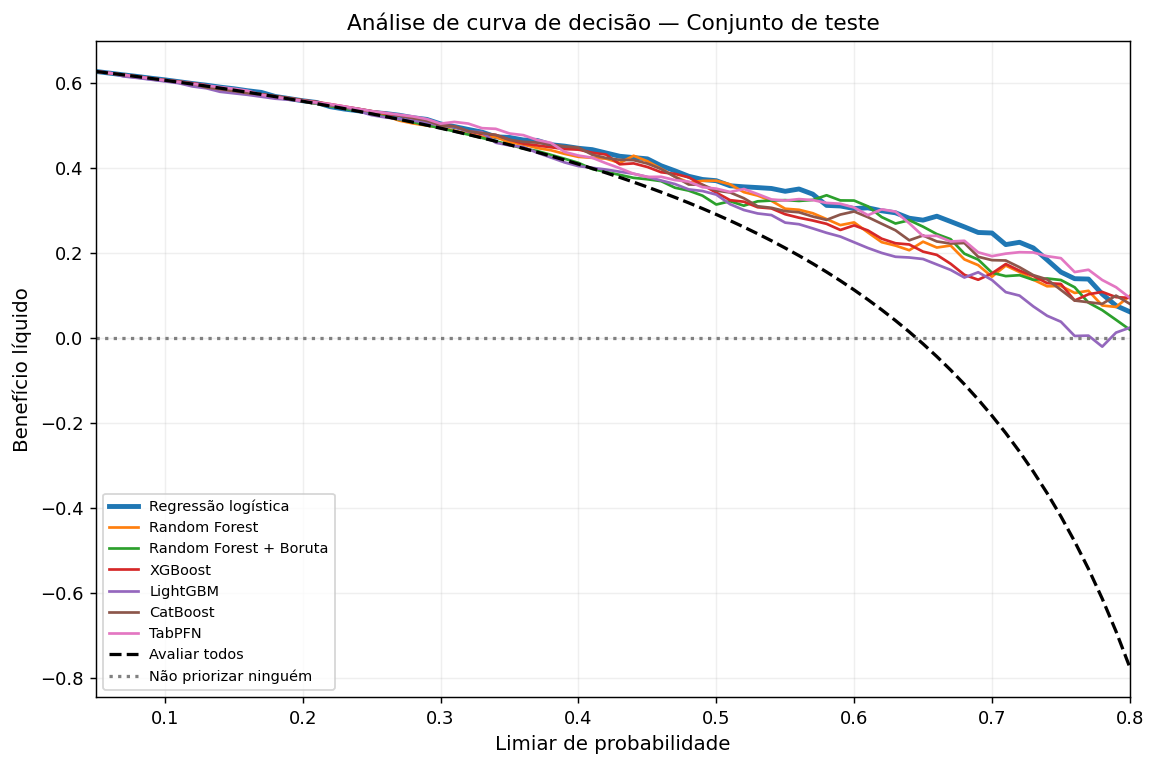


BENEFÍCIO LÍQUIDO POR LIMIAR


,limiar,Avaliar todos,Não priorizar ninguém,Regressão logística,Random Forest,Random Forest + Boruta,XGBoost,LightGBM,CatBoost,TabPFN
5,0.1,0.6054,0.0,0.6064,0.6054,0.6054,0.6059,0.6028,0.6059,0.6054
15,0.2,0.5561,0.0,0.5572,0.5561,0.5561,0.5584,0.5561,0.5584,0.5572
25,0.3,0.4927,0.0,0.5027,0.4940,0.4927,0.4993,0.4993,0.4993,0.5033
35,0.4,0.4081,0.0,0.4455,0.4252,0.4112,0.4424,0.4034,0.4470,0.4283
45,0.5,0.2897,0.0,0.3692,0.3692,0.3131,0.3411,0.3364,0.3458,0.3505
55,0.6,0.1121,0.0,0.3037,0.2710,0.3224,0.2640,0.2243,0.2967,0.3061



ARQUIVOS SALVOS
/content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/metricas_teste/DCA_sete_modelos_teste.csv
/content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/metricas_teste/DCA_sete_modelos_teste.png
/content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/metricas_teste/DCA_sete_modelos_teste.pdf

DCA concluída sem retreinamento dos modelos.


In [5]:

# ============================================================
# BLOCO 7E — DECISION CURVE ANALYSIS (DCA)
# Sete modelos | Conjunto de teste (n = 214)
#
# NÃO executa Optuna, fit, predict_proba ou nova divisão.
# Lê exclusivamente as probabilidades salvas pelo BLOCO 7A.
# Salva gráfico PNG/PDF e resultados em CSV.
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# 1. Localizar os resultados definitivos do Bloco 7A
# ------------------------------------------------------------
ID_EXECUCAO_DCA = "20261031_001033_d5dd674c"

PASTA_DCA = os.path.join(
    "/content/drive/MyDrive/Gitrub",
    "resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026",
    "execucoes",
    ID_EXECUCAO_DCA,
    "metricas_teste"
)

ARQUIVO_PROB = os.path.join(
    PASTA_DCA,
    "probabilidades_sete_modelos.joblib"
)

if not os.path.isfile(ARQUIVO_PROB):
    raise FileNotFoundError(
        "Arquivo de probabilidades não encontrado:\n"
        + ARQUIVO_PROB
        + "\nConfira o ID da execução e se o Drive está montado."
    )

dados = joblib.load(ARQUIVO_PROB)

# ------------------------------------------------------------
# 2. Recuperar desfecho e probabilidades do teste
# ------------------------------------------------------------
y_test = np.asarray(dados["y_teste"], dtype=int).ravel()
probs = dados["p_teste"]
nomes = list(dados["modelos"])

modelos_esperados = [
    "Regressão logística",
    "Random Forest",
    "Random Forest + Boruta",
    "XGBoost",
    "LightGBM",
    "CatBoost",
    "TabPFN"
]

if len(y_test) != 214:
    raise RuntimeError(
        f"Esperados 214 pacientes; encontrados {len(y_test)}."
    )

if np.sum(y_test == 1) != 138:
    raise RuntimeError(
        "O número de pacientes com indicação cirúrgica "
        "não corresponde ao teste original (138)."
    )

if set(np.unique(y_test)) != {0, 1}:
    raise RuntimeError("Desfecho não é binário 0/1.")

if set(nomes) != set(modelos_esperados):
    raise RuntimeError(
        f"Modelos inesperados no arquivo: {nomes}"
    )

probs = {
    nome: np.asarray(probs[nome], dtype=float).ravel()
    for nome in modelos_esperados
}

for nome, p in probs.items():
    if (
        len(p) != len(y_test)
        or not np.isfinite(p).all()
        or np.any((p < 0) | (p > 1))
    ):
        raise RuntimeError(
            f"Probabilidades inválidas: {nome}"
        )

# Conferência contra a AUROC final do artigo
auc_rl = roc_auc_score(
    y_test, probs["Regressão logística"]
)

if not np.isclose(auc_rl, 0.781, atol=0.001):
    raise RuntimeError(
        f"AUROC da regressão logística = {auc_rl:.6f}. "
        "Não corresponde à análise principal final. "
        "Verifique a execução antes de continuar."
    )

print("DADOS VALIDADOS")
print("Execução:", ID_EXECUCAO_DCA)
print("Pacientes:", len(y_test))
print("Com indicação:", int(y_test.sum()))
print("Sem indicação:", int((y_test == 0).sum()))
print("Prevalência:", f"{y_test.mean():.2%}")
print("AUROC RL:", f"{auc_rl:.3f}")
print("Modelos:", len(probs))

# ------------------------------------------------------------
# 3. Calcular benefício líquido
# Referência 21: Vickers & Elkin (2006)
# ------------------------------------------------------------
def beneficio_liquido(y, p, limiar):
    """
    Net benefit = TP/N - FP/N * limiar/(1-limiar)
    A ação positiva é priorizar avaliação cirúrgica.
    """
    pred = p >= limiar

    tp = np.sum((pred == 1) & (y == 1))
    fp = np.sum((pred == 1) & (y == 0))

    n = len(y)

    return (
        tp / n
        - (fp / n) * (limiar / (1 - limiar))
    )

# Intervalo exploratório, não escolhido por desempenho.
# Pode ser alterado conforme justificativa clínica.
limiares = np.arange(0.05, 0.801, 0.01)

prevalencia = float(y_test.mean())

registros = []

for pt in limiares:

    # Estratégia: priorizar todos
    nb_todos = (
        prevalencia
        - (1 - prevalencia) * (pt / (1 - pt))
    )

    linha = {
        "limiar": round(float(pt), 4),
        "Avaliar todos": float(nb_todos),
        "Não priorizar ninguém": 0.0
    }

    for nome in modelos_esperados:
        linha[nome] = beneficio_liquido(
            y_test, probs[nome], pt
        )

    registros.append(linha)

df_dca = pd.DataFrame(registros)

# ------------------------------------------------------------
# 4. Gráfico DCA
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=130)

for nome in modelos_esperados:
    espessura = (
        2.7 if nome == "Regressão logística" else 1.5
    )

    ax.plot(
        df_dca["limiar"],
        df_dca[nome],
        linewidth=espessura,
        label=nome
    )

ax.plot(
    df_dca["limiar"],
    df_dca["Avaliar todos"],
    color="black",
    linestyle="--",
    linewidth=1.8,
    label="Avaliar todos"
)

ax.axhline(
    0,
    color="gray",
    linestyle=":",
    linewidth=1.8,
    label="Não priorizar ninguém"
)

ax.set_xlabel("Limiar de probabilidade", fontsize=11)
ax.set_ylabel("Benefício líquido", fontsize=11)
ax.set_title(
    "Análise de curva de decisão — Conjunto de teste",
    fontsize=12
)

ax.set_xlim(0.05, 0.80)
ax.grid(alpha=0.2)
ax.legend(fontsize=8, loc="best")

plt.tight_layout()

# ------------------------------------------------------------
# 5. Salvar resultados na execução original
# ------------------------------------------------------------
os.makedirs(PASTA_DCA, exist_ok=True)

caminho_csv = os.path.join(
    PASTA_DCA,
    "DCA_sete_modelos_teste.csv"
)

caminho_png = os.path.join(
    PASTA_DCA,
    "DCA_sete_modelos_teste.png"
)

caminho_pdf = os.path.join(
    PASTA_DCA,
    "DCA_sete_modelos_teste.pdf"
)

df_dca.to_csv(
    caminho_csv,
    index=False,
    encoding="utf-8-sig"
)

fig.savefig(
    caminho_png,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    caminho_pdf,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. Resultados em limiares de referência
# ------------------------------------------------------------
limiares_resumo = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]

resumo_dca = df_dca.loc[
    df_dca["limiar"].round(2).isin(limiares_resumo)
].copy()

print("\nBENEFÍCIO LÍQUIDO POR LIMIAR")
display(resumo_dca.round(4))

print("\nARQUIVOS SALVOS")
print(caminho_csv)
print(caminho_png)
print(caminho_pdf)

print("\nDCA concluída sem retreinamento dos modelos.")


In [6]:

# ============================================================
# SALVAR RESULTADOS DA DCA NO GOOGLE DRIVE
# Não recalcula os modelos nem a DCA
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# Pasta da execução original
PASTA_SAIDA = (
    "/content/drive/MyDrive/Gitrub/"
    "resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/"
    "execucoes/20261031_001033_d5dd674c/"
    "metricas_teste/DCA"
)

os.makedirs(PASTA_SAIDA, exist_ok=True)

# 1. Salvar tabela completa
arquivo_csv = os.path.join(
    PASTA_SAIDA, "DCA_sete_modelos_teste.csv"
)

df_dca.to_csv(
    arquivo_csv,
    index=False,
    encoding="utf-8-sig"
)

# 2. Salvar tabela resumida
arquivo_resumo = os.path.join(
    PASTA_SAIDA, "DCA_resumo_limiares.csv"
)

resumo_dca.to_csv(
    arquivo_resumo,
    index=False,
    encoding="utf-8-sig"
)

# 3. Salvar gráfico em PNG e PDF
arquivo_png = os.path.join(
    PASTA_SAIDA, "DCA_sete_modelos_teste.png"
)

arquivo_pdf = os.path.join(
    PASTA_SAIDA, "DCA_sete_modelos_teste.pdf"
)

fig.savefig(
    arquivo_png,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    arquivo_pdf,
    bbox_inches="tight",
    facecolor="white"
)

# 4. Confirmar que os arquivos foram salvos
print("RESULTADOS SALVOS NO GOOGLE DRIVE\n")

for arquivo in [
    arquivo_csv,
    arquivo_resumo,
    arquivo_png,
    arquivo_pdf
]:
    if os.path.isfile(arquivo):
        print("OK:", arquivo)
    else:
        print("ERRO:", arquivo)


RESULTADOS SALVOS NO GOOGLE DRIVE

OK: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/metricas_teste/DCA/DCA_sete_modelos_teste.csv
OK: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/metricas_teste/DCA/DCA_resumo_limiares.csv
OK: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/metricas_teste/DCA/DCA_sete_modelos_teste.png
OK: /content/drive/MyDrive/Gitrub/resultados_EI_OPTUNA_FINAL_CORRIGIDO_2026/execucoes/20261031_001033_d5dd674c/metricas_teste/DCA/DCA_sete_modelos_teste.pdf
